In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_removaldisp.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_cgrefcodes.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_structures.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_platformincs.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_authorityhist.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_ruers.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_inccount.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_leases.txt
/kaggle/input/datasets/kabil908/bsee-ds/PlatStrucRawData/PlatStrucRawData/mv_platstruc_rightofways.txt
/kaggle/input/datasets/kabil908/bsee-ds/ProdByPlatformRawData/ProdByPlatformRawData/mv

In [5]:
"""Build a leakage-safe BSEE platform-year modelling table on Kaggle.

Upload this file to a Kaggle notebook and run:

    %run /path/to/kaggle_bsee_preprocessing.py

The script preserves all raw files and writes processed CSV files plus an audit
report under ``data/processed``. It intentionally uses only information known
by the end of year t to predict non-compliance outcomes in year t+1.
"""

from __future__ import annotations

import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd


LOG = logging.getLogger("bsee-preprocessing")
NA_VALUES = ["", " ", "NA", "N/A", "NULL", "None", "UNKNOWN"]


def clean_text(series: pd.Series) -> pd.Series:
    """Trim text while retaining pandas' nullable string representation."""
    return series.astype("string").str.strip().replace("", pd.NA)


def clean_identifier(series: pd.Series, width: int | None = None) -> pd.Series:
    """Normalize identifiers without converting missing values into strings."""
    result = clean_text(series)
    result = result.str.replace(r"\.0$", "", regex=True)
    if width is not None:
        result = result.str.zfill(width)
    return result


def read_csv(path: Path, usecols: list[str] | None = None) -> pd.DataFrame:
    LOG.info("Reading %s", path.name)
    return pd.read_csv(
        path,
        usecols=usecols,
        dtype="string",
        encoding="cp1252",
        na_values=NA_VALUES,
        keep_default_na=True,
        low_memory=False,
    )


def find_table(raw_dir: Path, filename: str) -> Path:
    """Find a BSEE table under either the local or nested Kaggle layout."""
    matches = list(raw_dir.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Could not find {filename!r} below {raw_dir}")
    if len(matches) > 1:
        raise RuntimeError(f"Found multiple copies of {filename!r}: {matches}")
    return matches[0]


def to_number(frame: pd.DataFrame, columns: list[str]) -> None:
    for column in columns:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")


def platform_key(complex_id: pd.Series, structure_number: pd.Series) -> pd.Series:
    complex_clean = clean_identifier(complex_id)
    structure_clean = clean_identifier(structure_number)
    key = complex_clean + "::" + structure_clean
    return key.where(complex_clean.notna() & structure_clean.notna())


def aggregate_production(path: Path, chunksize: int) -> pd.DataFrame:
    columns = [
        "COMPLEX_ID_NUM", "STRUCTURE_NUMBER", "AREA_CODE", "BLOCK_NUMBER",
        "LEASE_NUMBER", "STRUCTURE_NAME", "INSTALL_DATE", "REMOVAL_DATE",
        "PF_OPERATOR", "PF_OPERATOR_NUM", "PRODUCTION_DATE", "PRODUCING_WELLS",
        "BOPD", "MCFPD", "BOEPD", "BWPD", "REGION_CODE",
    ]
    partials: list[pd.DataFrame] = []

    LOG.info("Aggregating platform production in chunks")
    for chunk in pd.read_csv(
        path,
        usecols=columns,
        dtype="string",
        encoding="cp1252",
        na_values=NA_VALUES,
        chunksize=chunksize,
        low_memory=False,
    ):
        chunk["platform_id"] = platform_key(
            chunk["COMPLEX_ID_NUM"], chunk["STRUCTURE_NUMBER"]
        )
        chunk["production_date"] = pd.to_datetime(
            chunk["PRODUCTION_DATE"], errors="coerce"
        )
        chunk["year"] = chunk["production_date"].dt.year.astype("Int64")
        chunk["operator_id"] = clean_identifier(chunk["PF_OPERATOR_NUM"], width=5)
        chunk["lease_number"] = clean_identifier(chunk["LEASE_NUMBER"])
        chunk["area_code"] = clean_text(chunk["AREA_CODE"])
        chunk["block_number"] = clean_identifier(chunk["BLOCK_NUMBER"])
        chunk["region_code"] = clean_text(chunk["REGION_CODE"])
        chunk["operator_name"] = clean_text(chunk["PF_OPERATOR"])
        chunk["structure_name"] = clean_text(chunk["STRUCTURE_NAME"])

        numeric = ["PRODUCING_WELLS", "BOPD", "MCFPD", "BOEPD", "BWPD"]
        to_number(chunk, numeric)
        chunk = chunk.dropna(subset=["platform_id", "year"])

        grouped = chunk.groupby(["platform_id", "year"], observed=True).agg(
            active_months=("production_date", "nunique"),
            producing_wells_mean=("PRODUCING_WELLS", "mean"),
            producing_wells_max=("PRODUCING_WELLS", "max"),
            bopd_mean=("BOPD", "mean"),
            bopd_max=("BOPD", "max"),
            mcfd_mean=("MCFPD", "mean"),
            mcfd_max=("MCFPD", "max"),
            boepd_mean=("BOEPD", "mean"),
            bwpd_mean=("BWPD", "mean"),
            operator_id=("operator_id", "last"),
            operator_name=("operator_name", "last"),
            lease_number=("lease_number", "last"),
            area_code=("area_code", "last"),
            block_number=("block_number", "last"),
            region_code=("region_code", "last"),
            structure_name=("structure_name", "last"),
        ).reset_index()
        partials.append(grouped)

    production = pd.concat(partials, ignore_index=True)
    # A platform-year may span input chunks; aggregate the partial results again.
    weighted_columns = [
        "producing_wells_mean", "bopd_mean", "mcfd_mean", "boepd_mean", "bwpd_mean"
    ]
    for column in weighted_columns:
        production[f"_{column}_weighted"] = production[column] * production["active_months"]

    aggregation: dict[str, tuple[str, str]] = {
        "active_months": ("active_months", "sum"),
        "producing_wells_max": ("producing_wells_max", "max"),
        "bopd_max": ("bopd_max", "max"),
        "mcfd_max": ("mcfd_max", "max"),
    }
    for column in weighted_columns:
        aggregation[f"_{column}_weighted"] = (f"_{column}_weighted", "sum")
    for column in [
        "operator_id", "operator_name", "lease_number", "area_code",
        "block_number", "region_code", "structure_name",
    ]:
        aggregation[column] = (column, "last")

    production = production.groupby(
        ["platform_id", "year"], observed=True
    ).agg(**aggregation).reset_index()
    for column in weighted_columns:
        production[column] = production[f"_{column}_weighted"] / production["active_months"]
        production.drop(columns=f"_{column}_weighted", inplace=True)

    production["year"] = production["year"].astype(int)
    return production


def load_structures(path: Path) -> pd.DataFrame:
    columns = [
        "COMPLEX_ID_NUM", "STRUCTURE_NUMBER", "STRUC_TYPE_CODE", "MAJ_STRUC_FLAG",
        "INSTALL_DATE", "REMOVAL_DATE", "DISTRICT_CODE", "HELIPORT_FLAG",
        "LEASE_NUMBER", "WATER_DEPTH", "LATITUDE", "LONGITUDE",
        "ATTENDED_8_HR_FL", "MANNED_24_HR_FL",
    ]
    structures = read_csv(path, columns)
    structures["platform_id"] = platform_key(
        structures["COMPLEX_ID_NUM"], structures["STRUCTURE_NUMBER"]
    )
    structures["install_date"] = pd.to_datetime(structures["INSTALL_DATE"], errors="coerce")
    structures["removal_date"] = pd.to_datetime(structures["REMOVAL_DATE"], errors="coerce")
    structures["lease_number_structure"] = clean_identifier(structures["LEASE_NUMBER"])
    rename = {
        "STRUC_TYPE_CODE": "structure_type",
        "MAJ_STRUC_FLAG": "major_structure_flag",
        "DISTRICT_CODE": "district_code",
        "HELIPORT_FLAG": "heliport_flag",
        "WATER_DEPTH": "water_depth",
        "LATITUDE": "latitude",
        "LONGITUDE": "longitude",
        "ATTENDED_8_HR_FL": "attended_8hr_flag",
        "MANNED_24_HR_FL": "manned_24hr_flag",
    }
    structures.rename(columns=rename, inplace=True)
    to_number(structures, ["water_depth", "latitude", "longitude"])
    keep = ["platform_id", "install_date", "removal_date", "lease_number_structure"] + list(rename.values())
    structures = structures[keep].dropna(subset=["platform_id"])
    return structures.drop_duplicates("platform_id", keep="last")


def load_platform_incs(path: Path) -> pd.DataFrame:
    columns = [
        "ID_NUMBER", "STRUCTURE_NUMBER", "INC_NUMBER", "INC_ENFRC_CODE",
        "MMS_COMPANY_NUM", "INC_ISSUE_DATE", "INSP_DATE",
    ]
    incs = read_csv(path, columns)
    incs["platform_id"] = platform_key(incs["ID_NUMBER"], incs["STRUCTURE_NUMBER"])
    incs["inc_date"] = pd.to_datetime(incs["INC_ISSUE_DATE"], errors="coerce")
    incs["year"] = incs["inc_date"].dt.year.astype("Int64")
    incs["operator_id_inc"] = clean_identifier(incs["MMS_COMPANY_NUM"], width=5)
    incs["enforcement_code"] = clean_text(incs["INC_ENFRC_CODE"])
    incs = incs.dropna(subset=["platform_id", "year"])
    result = incs.groupby(["platform_id", "year"], observed=True).agg(
        inc_count=("INC_NUMBER", "count"),
        enforcement_code_count=("enforcement_code", "nunique"),
        operator_id_inc=("operator_id_inc", "last"),
    ).reset_index()
    result["year"] = result["year"].astype(int)
    return result


def load_operator_activity(inspections_path: Path, incs_path: Path) -> pd.DataFrame:
    inspections = read_csv(inspections_path)
    inspections["date"] = pd.to_datetime(inspections["INS_DATE"], errors="coerce")
    inspections["year"] = inspections["date"].dt.year.astype("Int64")
    inspections["operator_id"] = clean_identifier(inspections["BUS_ASC_CODE"], width=5)
    to_number(inspections, ["FACILITIES_INSPECTED", "INSPECTION_RECORDS", "INSPECTION_TYPES"])
    inspections = inspections.dropna(subset=["operator_id", "year"])
    inspections = inspections.groupby(["operator_id", "year"], observed=True).agg(
        operator_facilities_inspected=("FACILITIES_INSPECTED", "sum"),
        operator_inspection_records=("INSPECTION_RECORDS", "sum"),
        operator_inspection_types=("INSPECTION_TYPES", "sum"),
    ).reset_index()

    incs = read_csv(incs_path)
    incs["date"] = pd.to_datetime(incs["INC_DATE"], errors="coerce")
    incs["year"] = incs["date"].dt.year.astype("Int64")
    incs["operator_id"] = clean_identifier(incs["BUS_ASC_CODE"], width=5)
    to_number(incs, ["WARNING_INCS", "COMP_SHUTIN_INCS", "FAC_SHUTIN_INCS"])
    incs = incs.dropna(subset=["operator_id", "year"])
    incs = incs.groupby(["operator_id", "year"], observed=True).agg(
        operator_warning_incs=("WARNING_INCS", "sum"),
        operator_component_shutin_incs=("COMP_SHUTIN_INCS", "sum"),
        operator_facility_shutin_incs=("FAC_SHUTIN_INCS", "sum"),
    ).reset_index()

    activity = inspections.merge(incs, on=["operator_id", "year"], how="outer")
    activity["year"] = activity["year"].astype(int)
    return activity


def load_accidents(path: Path) -> pd.DataFrame:
    accidents = read_csv(path)
    accidents["date"] = pd.to_datetime(accidents["DATE_OCCURRED"], errors="coerce")
    accidents["year"] = accidents["date"].dt.year.astype("Int64")
    accidents["lease_number"] = clean_identifier(accidents["LEASE_NUMBER"])
    accidents = accidents.dropna(subset=["lease_number", "year"])
    result = accidents.groupby(["lease_number", "year"], observed=True).agg(
        investigated_accident_count=("ACCIDENT_TYPE", "size"),
        accident_type_count=("ACCIDENT_TYPE", "nunique"),
    ).reset_index()
    result["year"] = result["year"].astype(int)
    return result


def add_history_and_targets(panel: pd.DataFrame) -> pd.DataFrame:
    panel = panel.sort_values(["platform_id", "year"]).reset_index(drop=True)
    group = panel.groupby("platform_id", observed=True, sort=False)

    panel["previous_year_inc_count"] = group["inc_count"].shift(1)
    panel["inc_count_previous_3_observations"] = group["inc_count"].transform(
        lambda values: values.shift(1).rolling(3, min_periods=1).sum()
    )
    panel["previous_year_accident_count"] = group["investigated_accident_count"].shift(1)
    panel["production_change_bopd"] = group["bopd_mean"].pct_change(fill_method=None)
    panel["production_change_mcfd"] = group["mcfd_mean"].pct_change(fill_method=None)

    next_year = panel[["platform_id", "year", "inc_count"]].copy()
    next_year["year"] = next_year["year"] - 1
    next_year.rename(columns={"inc_count": "next_year_inc_count"}, inplace=True)
    panel = panel.merge(next_year, on=["platform_id", "year"], how="left")
    panel["next_year_any_inc"] = np.where(
        panel["next_year_inc_count"].notna(),
        (panel["next_year_inc_count"] > 0).astype("int8"),
        np.nan,
    )
    return panel


def build_dataset(raw_dir: Path, output_dir: Path, chunksize: int) -> pd.DataFrame:
    production = aggregate_production(
        find_table(raw_dir, "mv_prod_by_platform_all.txt"), chunksize
    )
    structures = load_structures(
        find_table(raw_dir, "mv_platstruc_structures.txt")
    )
    platform_incs = load_platform_incs(
        find_table(raw_dir, "mv_platstruc_platformincs.txt")
    )
    operator_activity = load_operator_activity(
        find_table(raw_dir, "mv_insp_by_oper.txt"),
        find_table(raw_dir, "mv_incs_by_oper.txt"),
    )
    accidents = load_accidents(
        find_table(raw_dir, "mv_acc_investigations.txt")
    )

    panel = production.merge(structures, on="platform_id", how="left", validate="many_to_one")
    panel["lease_number"] = panel["lease_number"].fillna(panel["lease_number_structure"])
    panel.drop(columns="lease_number_structure", inplace=True)
    panel["platform_age"] = panel["year"] - panel["install_date"].dt.year
    panel["years_until_removal"] = panel["removal_date"].dt.year - panel["year"]

    panel = panel.merge(platform_incs, on=["platform_id", "year"], how="left", validate="one_to_one")
    panel["operator_id"] = panel["operator_id"].fillna(panel["operator_id_inc"])
    panel.drop(columns="operator_id_inc", inplace=True)
    panel = panel.merge(operator_activity, on=["operator_id", "year"], how="left", validate="many_to_one")
    panel = panel.merge(accidents, on=["lease_number", "year"], how="left", validate="many_to_one")

    count_columns = [
        "inc_count", "enforcement_code_count", "operator_facilities_inspected",
        "operator_inspection_records", "operator_inspection_types",
        "operator_warning_incs", "operator_component_shutin_incs",
        "operator_facility_shutin_incs", "investigated_accident_count",
        "accident_type_count",
    ]
    panel[count_columns] = panel[count_columns].fillna(0)
    panel["any_inc"] = (panel["inc_count"] > 0).astype("int8")
    panel = add_history_and_targets(panel)

    output_dir.mkdir(parents=True, exist_ok=True)
    full_path = output_dir / "bsee_platform_year_full.csv.gz"
    model_path = output_dir / "bsee_platform_year_model.csv.gz"
    panel.to_csv(full_path, index=False, compression="gzip")
    model = panel.loc[panel["next_year_inc_count"].notna()].copy()
    model.to_csv(model_path, index=False, compression="gzip")

    audit = {
        "rows_full": int(len(panel)),
        "rows_model": int(len(model)),
        "platforms": int(panel["platform_id"].nunique()),
        "minimum_year": int(panel["year"].min()),
        "maximum_year": int(panel["year"].max()),
        "current_inc_positive_rate": float(panel["any_inc"].mean()),
        "next_year_inc_positive_rate": float(model["next_year_any_inc"].mean()),
        "missing_percent": {
            column: round(float(panel[column].isna().mean() * 100), 3)
            for column in panel.columns
        },
    }
    (output_dir / "preprocessing_audit.json").write_text(
        json.dumps(audit, indent=2), encoding="utf-8"
    )
    LOG.info("Wrote %s", full_path)
    LOG.info("Wrote %s", model_path)
    return panel


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
    raw_dir = Path("/kaggle/input/datasets/kabil908/bsee-ds")
    output_dir = Path("/kaggle/working/bsee_processed")
    chunksize = 250_000

    if not raw_dir.exists():
        raise FileNotFoundError(f"BSEE Kaggle input directory not found: {raw_dir}")

    LOG.info("Input directory: %s", raw_dir)
    LOG.info("Output directory: %s", output_dir)
    panel = build_dataset(raw_dir, output_dir, chunksize)
    LOG.info("Finished: %s platform-year rows", f"{len(panel):,}")


if __name__ == "__main__":
    main()


INFO Input directory: /kaggle/input/datasets/kabil908/bsee-ds
INFO Output directory: /kaggle/working/bsee_processed
INFO Aggregating platform production in chunks
INFO Reading mv_platstruc_structures.txt
INFO Reading mv_platstruc_platformincs.txt
INFO Reading mv_insp_by_oper.txt
/tmp/ipykernel_49/3999677067.py:221: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  inspections["date"] = pd.to_datetime(inspections["INS_DATE"], errors="coerce")
INFO Reading mv_incs_by_oper.txt
INFO Reading mv_acc_investigations.txt
INFO Wrote /kaggle/working/bsee_processed/bsee_platform_year_full.csv.gz
INFO Wrote /kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz
INFO Finished: 148,672 platform-year rows


In [6]:
from pathlib import Path
import json
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/bsee_processed")

model = pd.read_csv(
    OUTPUT_DIR / "bsee_platform_year_model.csv.gz",
    low_memory=False,
)

with open(
    OUTPUT_DIR / "preprocessing_audit.json",
    encoding="utf-8",
) as file:
    audit = json.load(file)

print("Shape:", model.shape)
print("Platforms:", model["platform_id"].nunique())
print("Years:", model["year"].min(), "-", model["year"].max())

print("\nTarget distribution:")
print(model["next_year_any_inc"].value_counts())

print("\nTarget percentages:")
print(
    model["next_year_any_inc"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDuplicate platform-years:")
print(model.duplicated(["platform_id", "year"]).sum())

display(model.head())


Shape: (141730, 49)
Platforms: 6158
Years: 1947 - 2025

Target distribution:
next_year_any_inc
0.0    115487
1.0     26243
Name: count, dtype: int64

Target percentages:
next_year_any_inc
0.0    81.48
1.0    18.52
Name: proportion, dtype: float64

Duplicate platform-years:
0


,platform_id,year,active_months,producing_wells_max,bopd_max,mcfd_max,operator_id,operator_name,lease_number,area_code,...,investigated_accident_count,accident_type_count,any_inc,previous_year_inc_count,inc_count_previous_3_observations,previous_year_accident_count,production_change_bopd,production_change_mcfd,next_year_inc_count,next_year_any_inc
0,10001::1,1972,9,2,102,23139,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN,0.0,0.0
1,10001::1,1973,11,2,29,3347,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.870370,-0.852270,0.0,0.0
2,10001::1,1974,12,2,2,3940,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.880952,0.062484,0.0,0.0
3,10001::1,1975,12,2,3,3271,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,1.200000,0.032670,0.0,0.0
4,10001::1,1976,12,2,2,2947,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.318182,-0.303032,0.0,0.0


In [7]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

OUTPUT_DIR = Path("/kaggle/working/bsee_processed")
ZIP_PATH = Path("/kaggle/working/bsee_preprocessed_dataset.zip")

files_to_package = [
    OUTPUT_DIR / "bsee_platform_year_full.csv.gz",
    OUTPUT_DIR / "bsee_platform_year_model.csv.gz",
    OUTPUT_DIR / "preprocessing_audit.json",
]

# Validate files before creating the archive
missing_files = [
    str(file_path)
    for file_path in files_to_package
    if not file_path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "The following output files are missing:\n"
        + "\n".join(missing_files)
    )

# Create ZIP archive
with ZipFile(
    ZIP_PATH,
    mode="w",
    compression=ZIP_DEFLATED,
    compresslevel=9,
) as zip_file:
    for file_path in files_to_package:
        zip_file.write(
            filename=file_path,
            arcname=file_path.name,
        )

# Verify ZIP contents
with ZipFile(ZIP_PATH, mode="r") as zip_file:
    bad_files = zip_file.testzip()
    archive_contents = zip_file.infolist()

if bad_files is not None:
    raise RuntimeError(f"Corrupted file detected: {bad_files}")

print("ZIP archive created successfully")
print("Path:", ZIP_PATH)
print(f"Size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")

print("\nArchive contents:")
for item in archive_contents:
    print(
        f"- {item.filename}: "
        f"{item.file_size / (1024**2):.2f} MB"
    )

display(FileLink(str(ZIP_PATH)))

ZIP archive created successfully
Path: /kaggle/working/bsee_preprocessed_dataset.zip
Size: 13.06 MB

Archive contents:
- bsee_platform_year_full.csv.gz: 6.63 MB
- bsee_platform_year_model.csv.gz: 6.42 MB
- preprocessing_audit.json: 0.00 MB


/kaggle/working/bsee_preprocessed_dataset.zip

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path("/kaggle/working/bsee_processed")
FIGURE_DIR = Path("/kaggle/working/bsee_eda_figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = DATA_DIR / "bsee_platform_year_model.csv.gz"

df = pd.read_csv(MODEL_PATH, low_memory=False)

print("Shape:", df.shape)
print("Platforms:", df["platform_id"].nunique())
print("Years:", df["year"].min(), "-", df["year"].max())
print("Duplicate platform-years:",
      df.duplicated(["platform_id", "year"]).sum())

display(df.head())

Shape: (141730, 49)
Platforms: 6158
Years: 1947 - 2025
Duplicate platform-years: 0


,platform_id,year,active_months,producing_wells_max,bopd_max,mcfd_max,operator_id,operator_name,lease_number,area_code,...,investigated_accident_count,accident_type_count,any_inc,previous_year_inc_count,inc_count_previous_3_observations,previous_year_accident_count,production_change_bopd,production_change_mcfd,next_year_inc_count,next_year_any_inc
0,10001::1,1972,9,2,102,23139,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,NaN,NaN,NaN,NaN,NaN,0.0,0.0
1,10001::1,1973,11,2,29,3347,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.870370,-0.852270,0.0,0.0
2,10001::1,1974,12,2,2,3940,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.880952,0.062484,0.0,0.0
3,10001::1,1975,12,2,3,3271,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,1.200000,0.032670,0.0,0.0
4,10001::1,1976,12,2,2,2947,40,Texaco Inc.,G01733,BA,...,0.0,0.0,0,0.0,0.0,0.0,-0.318182,-0.303032,0.0,0.0


In [9]:
TARGET = "next_year_any_inc"

# Exclude observations whose outcome year is incomplete
df = df[df["year"] <= 2024].copy()

# Retain the complete history for temporal coverage analysis
df_history = df.copy()

# Candidate modern study period
df_eda = df[df["year"] >= 1990].copy()

print("Complete historical sample:", df_history.shape)
print("Candidate 1990–2024 sample:", df_eda.shape)
print("Candidate platforms:", df_eda["platform_id"].nunique())

print("\nTarget distribution:")
display(
    df_eda[TARGET]
    .value_counts(dropna=False)
    .rename_axis("class")
    .to_frame("count")
    .assign(
        percentage=lambda x:
        (100 * x["count"] / x["count"].sum()).round(2)
    )
)

Complete historical sample: (141110, 49)
Candidate 1990–2024 sample: (88472, 49)
Candidate platforms: 5478

Target distribution:


,count,percentage
class,,
0.0,66676,75.36
1.0,21796,24.64


,dtype,missing_count,missing_percent,unique_values
removal_date,object,30973,35.01,3185
years_until_removal,float64,30973,35.01,84
production_change_bopd,float64,29518,33.36,43908
production_change_mcfd,float64,22987,25.98,58573
previous_year_inc_count,float64,2125,2.40,53
inc_count_previous_3_observations,float64,2125,2.40,90
previous_year_accident_count,float64,2125,2.40,6
attended_8hr_flag,object,1757,1.99,2
lease_number,object,1705,1.93,2560
heliport_flag,object,895,1.01,2


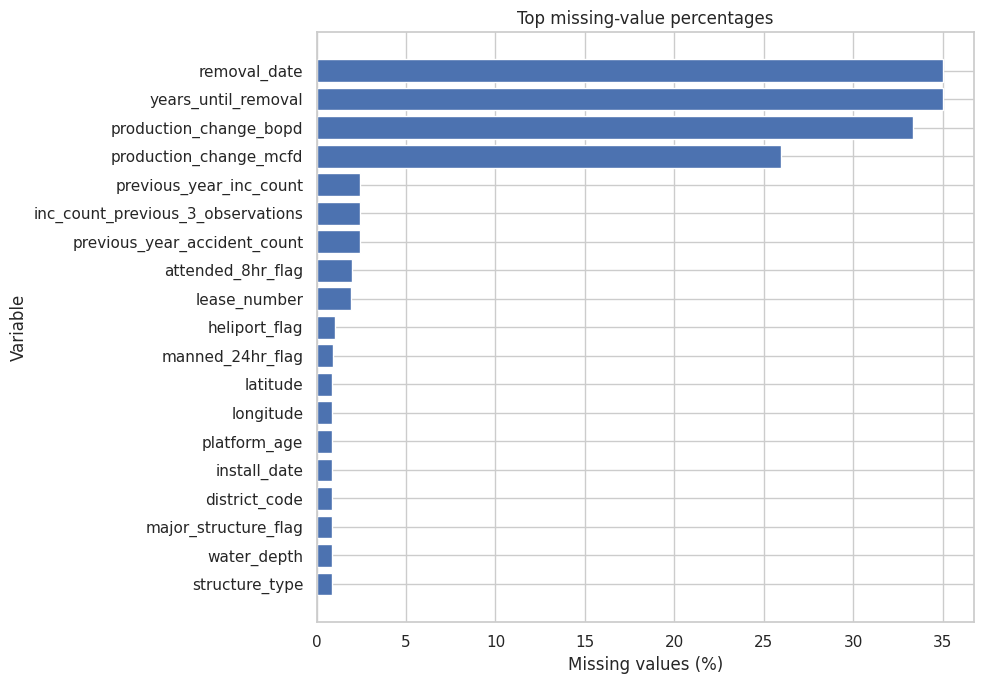

In [10]:
summary = pd.DataFrame({
    "dtype": df_eda.dtypes.astype(str),
    "missing_count": df_eda.isna().sum(),
    "missing_percent": df_eda.isna().mean().mul(100),
    "unique_values": df_eda.nunique(dropna=True),
})

summary = summary.sort_values(
    "missing_percent",
    ascending=False,
)

display(summary.round(2))

summary.to_csv(
    DATA_DIR / "eda_variable_summary.csv",
    index_label="variable",
)

missing_plot = (
    summary[summary["missing_percent"] > 0]
    .head(20)
    .sort_values("missing_percent")
)

plt.figure(figsize=(10, 7))
plt.barh(
    missing_plot.index,
    missing_plot["missing_percent"],
)
plt.xlabel("Missing values (%)")
plt.ylabel("Variable")
plt.title("Top missing-value percentages")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "01_missingness.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

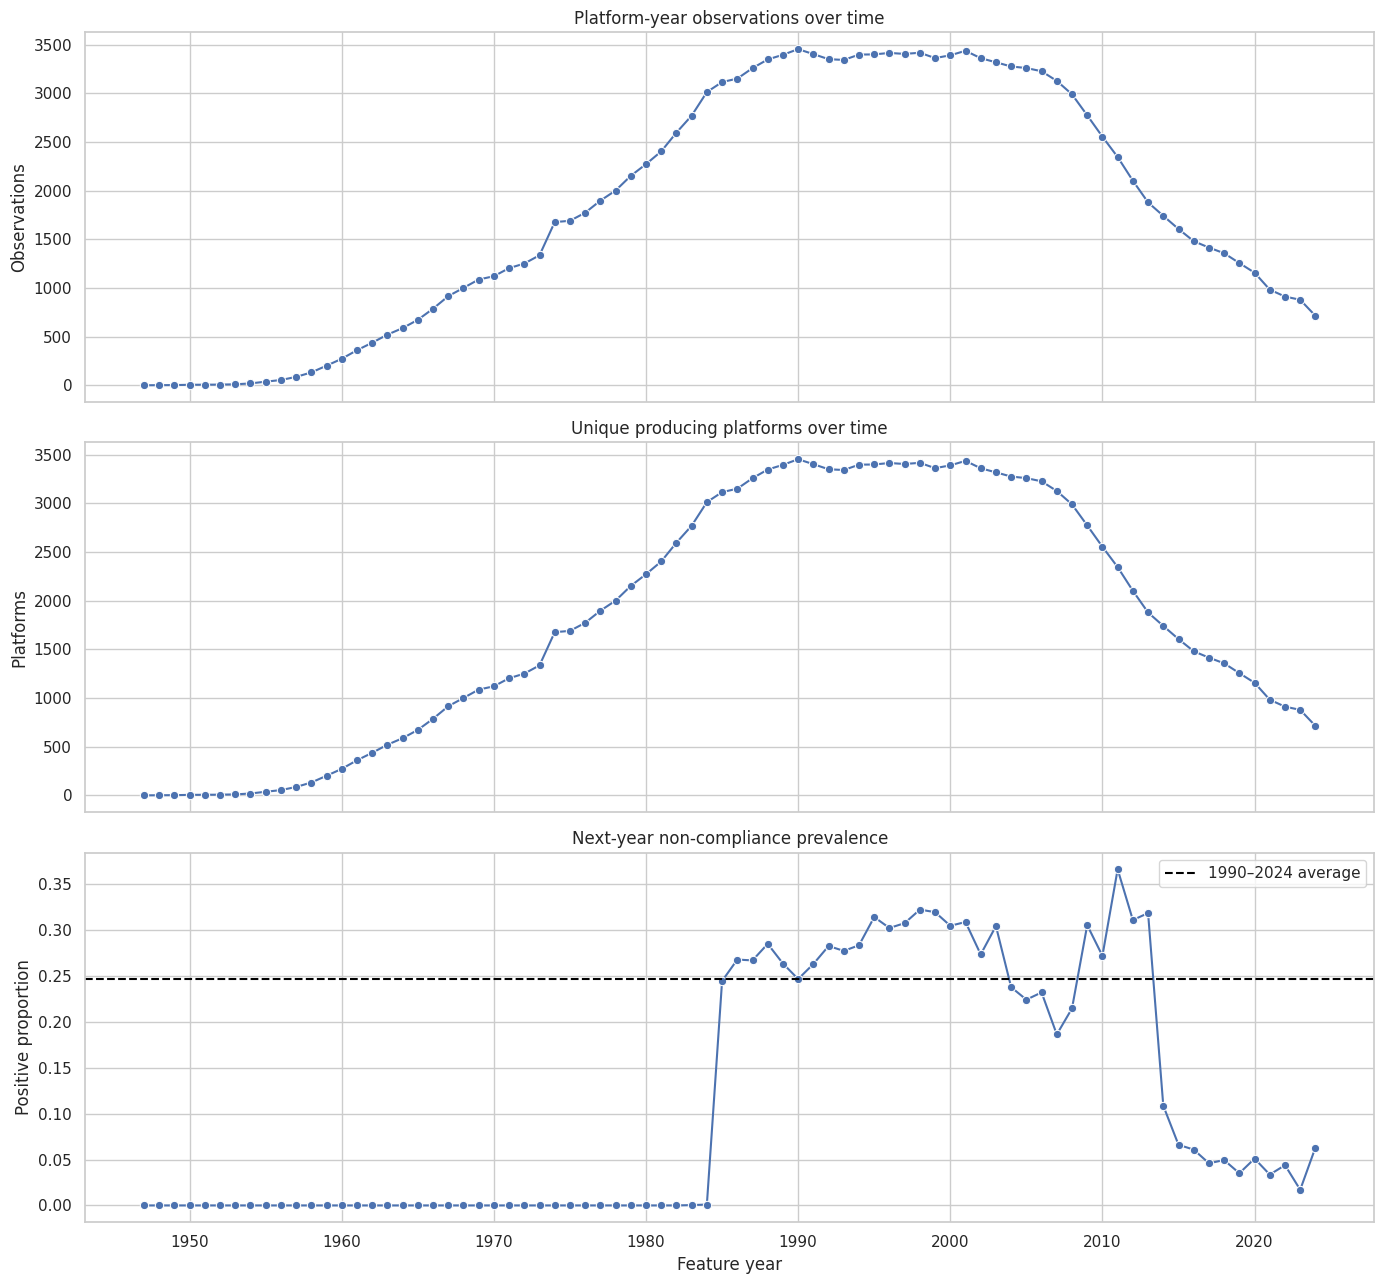

,year,observations,platforms,positive_cases,positive_rate,mean_inc_count
63,2010,2554,2554,694.0,0.271731,0.751762
64,2011,2345,2345,858.0,0.365885,0.950959
65,2012,2102,2102,653.0,0.310657,0.921979
66,2013,1879,1879,598.0,0.318254,0.873869
67,2014,1741,1741,189.0,0.108558,0.246410
68,2015,1606,1606,106.0,0.066002,0.180573
69,2016,1481,1481,90.0,0.060770,0.162053
70,2017,1415,1415,65.0,0.045936,0.071378
71,2018,1357,1357,67.0,0.049374,0.100221
72,2019,1256,1256,44.0,0.035032,0.050159


In [11]:
yearly = (
    df_history.groupby("year")
    .agg(
        observations=("platform_id", "size"),
        platforms=("platform_id", "nunique"),
        positive_cases=(TARGET, "sum"),
        positive_rate=(TARGET, "mean"),
        mean_inc_count=("next_year_inc_count", "mean"),
    )
    .reset_index()
)

yearly.to_csv(
    DATA_DIR / "eda_yearly_summary.csv",
    index=False,
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 13),
    sharex=True,
)

sns.lineplot(
    data=yearly,
    x="year",
    y="observations",
    marker="o",
    ax=axes[0],
)

axes[0].set_title("Platform-year observations over time")
axes[0].set_ylabel("Observations")

sns.lineplot(
    data=yearly,
    x="year",
    y="platforms",
    marker="o",
    ax=axes[1],
)

axes[1].set_title("Unique producing platforms over time")
axes[1].set_ylabel("Platforms")

sns.lineplot(
    data=yearly,
    x="year",
    y="positive_rate",
    marker="o",
    ax=axes[2],
)

axes[2].axhline(
    df_eda[TARGET].mean(),
    linestyle="--",
    color="black",
    label="1990–2024 average",
)

axes[2].set_title("Next-year non-compliance prevalence")
axes[2].set_ylabel("Positive proportion")
axes[2].set_xlabel("Feature year")
axes[2].legend()

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "02_temporal_coverage.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

display(yearly.tail(15))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness
active_months,88472.0,11.838,1.080,1.0,5.0,12.0,12.0,12.000,12.000,12.000,12.000,12.000,-7.582
producing_wells_mean,88472.0,1.951,3.434,0.0,0.0,0.0,0.0,1.000,2.000,8.000,17.583,49.333,4.184
bopd_mean,88472.0,576.012,4900.335,0.0,0.0,0.0,0.0,6.917,123.333,1178.871,9836.091,186785.750,18.417
mcfd_mean,88472.0,3400.089,14341.255,0.0,0.0,0.0,0.0,313.292,2234.000,14169.162,45928.346,801614.000,19.568
boepd_mean,88472.0,1181.007,6462.560,0.0,0.0,0.0,0.0,142.667,659.188,3552.921,17201.539,218855.083,15.443
bwpd_mean,88472.0,656.980,2414.475,0.0,0.0,0.0,0.0,21.833,427.083,2850.458,9675.638,99974.667,12.101
water_depth,87690.0,163.146,547.815,1.0,11.0,16.0,37.0,60.000,143.000,324.550,3216.000,9560.000,9.515
platform_age,87690.0,20.056,14.866,-19.0,-2.0,1.0,8.0,18.000,30.000,47.000,58.000,74.000,0.592
previous_year_inc_count,86347.0,0.839,2.520,0.0,0.0,0.0,0.0,0.000,1.000,5.000,11.000,102.000,7.848
inc_count_previous_3_observations,86347.0,2.495,5.410,0.0,0.0,0.0,0.0,0.000,3.000,12.000,26.000,123.000,5.286


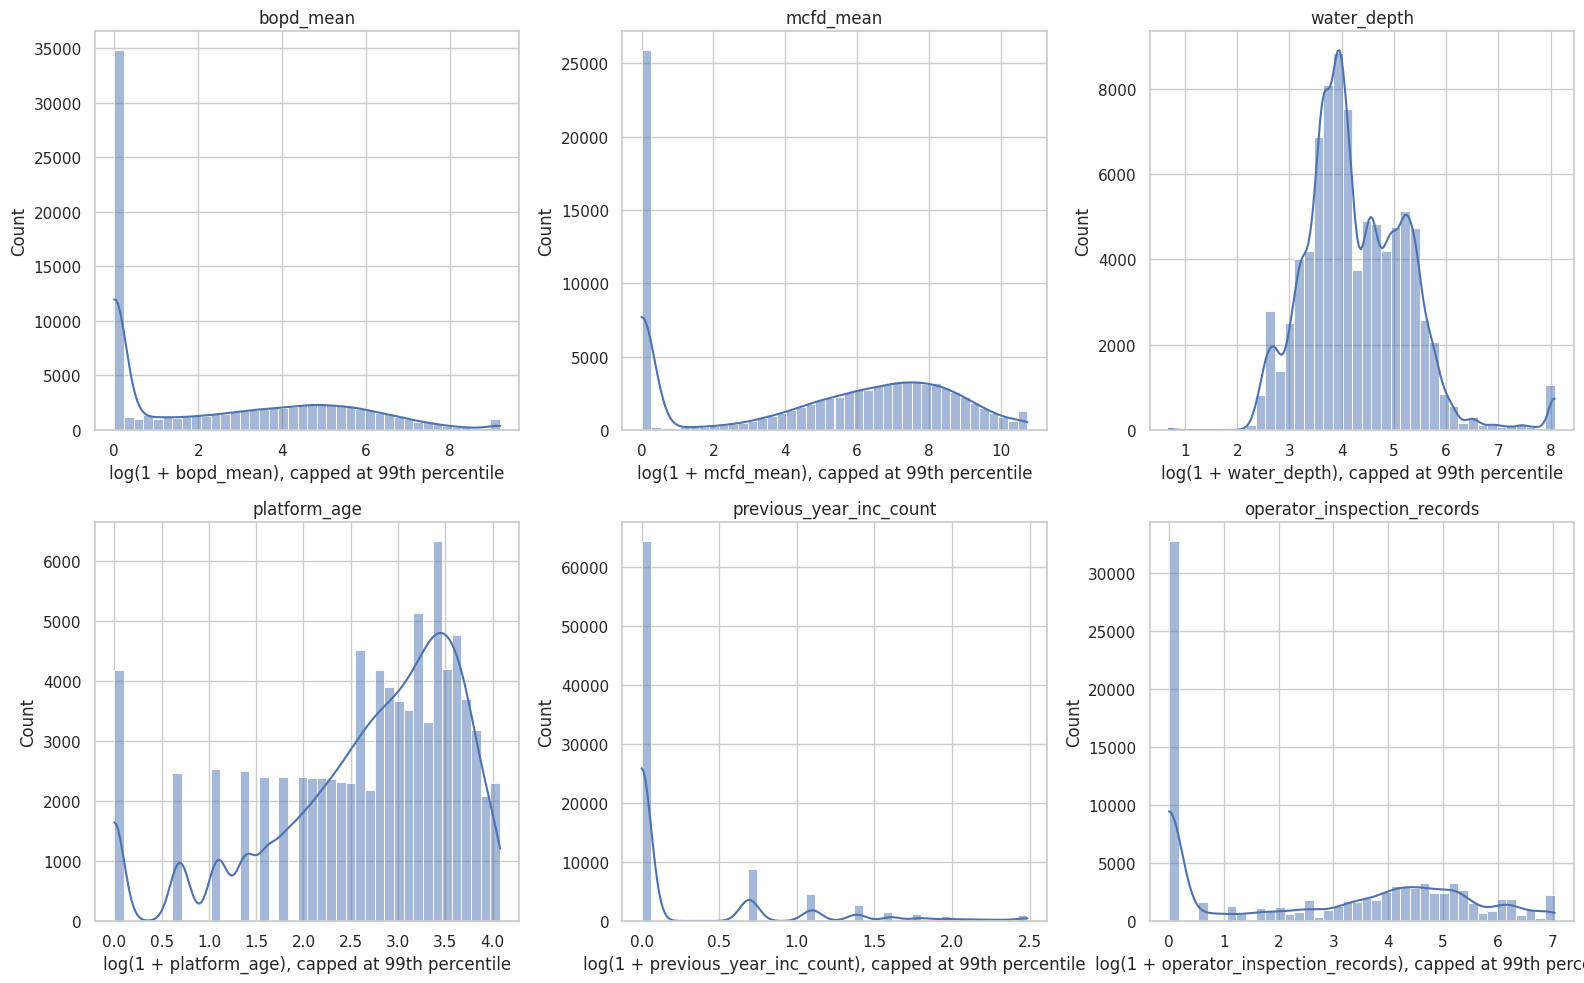

In [12]:
numeric_features = [
    "active_months",
    "producing_wells_mean",
    "bopd_mean",
    "mcfd_mean",
    "boepd_mean",
    "bwpd_mean",
    "water_depth",
    "platform_age",
    "previous_year_inc_count",
    "inc_count_previous_3_observations",
    "operator_inspection_records",
    "operator_warning_incs",
    "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
    "investigated_accident_count",
]

available_numeric = [
    column for column in numeric_features
    if column in df_eda.columns
]

description = (
    df_eda[available_numeric]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
)

description["skewness"] = df_eda[available_numeric].skew()
display(description.round(3))

description.to_csv(
    DATA_DIR / "eda_numeric_summary.csv",
)

plot_features = [
    "bopd_mean",
    "mcfd_mean",
    "water_depth",
    "platform_age",
    "previous_year_inc_count",
    "operator_inspection_records",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for axis, column in zip(axes, plot_features):
    values = pd.to_numeric(
        df_eda[column],
        errors="coerce",
    ).clip(lower=0)

    upper_limit = values.quantile(0.99)
    plot_values = values.clip(upper=upper_limit)

    sns.histplot(
        np.log1p(plot_values.dropna()),
        bins=40,
        kde=True,
        ax=axis,
    )

    axis.set_title(column)
    axis.set_xlabel(f"log(1 + {column}), capped at 99th percentile")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "03_numeric_distributions.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical un

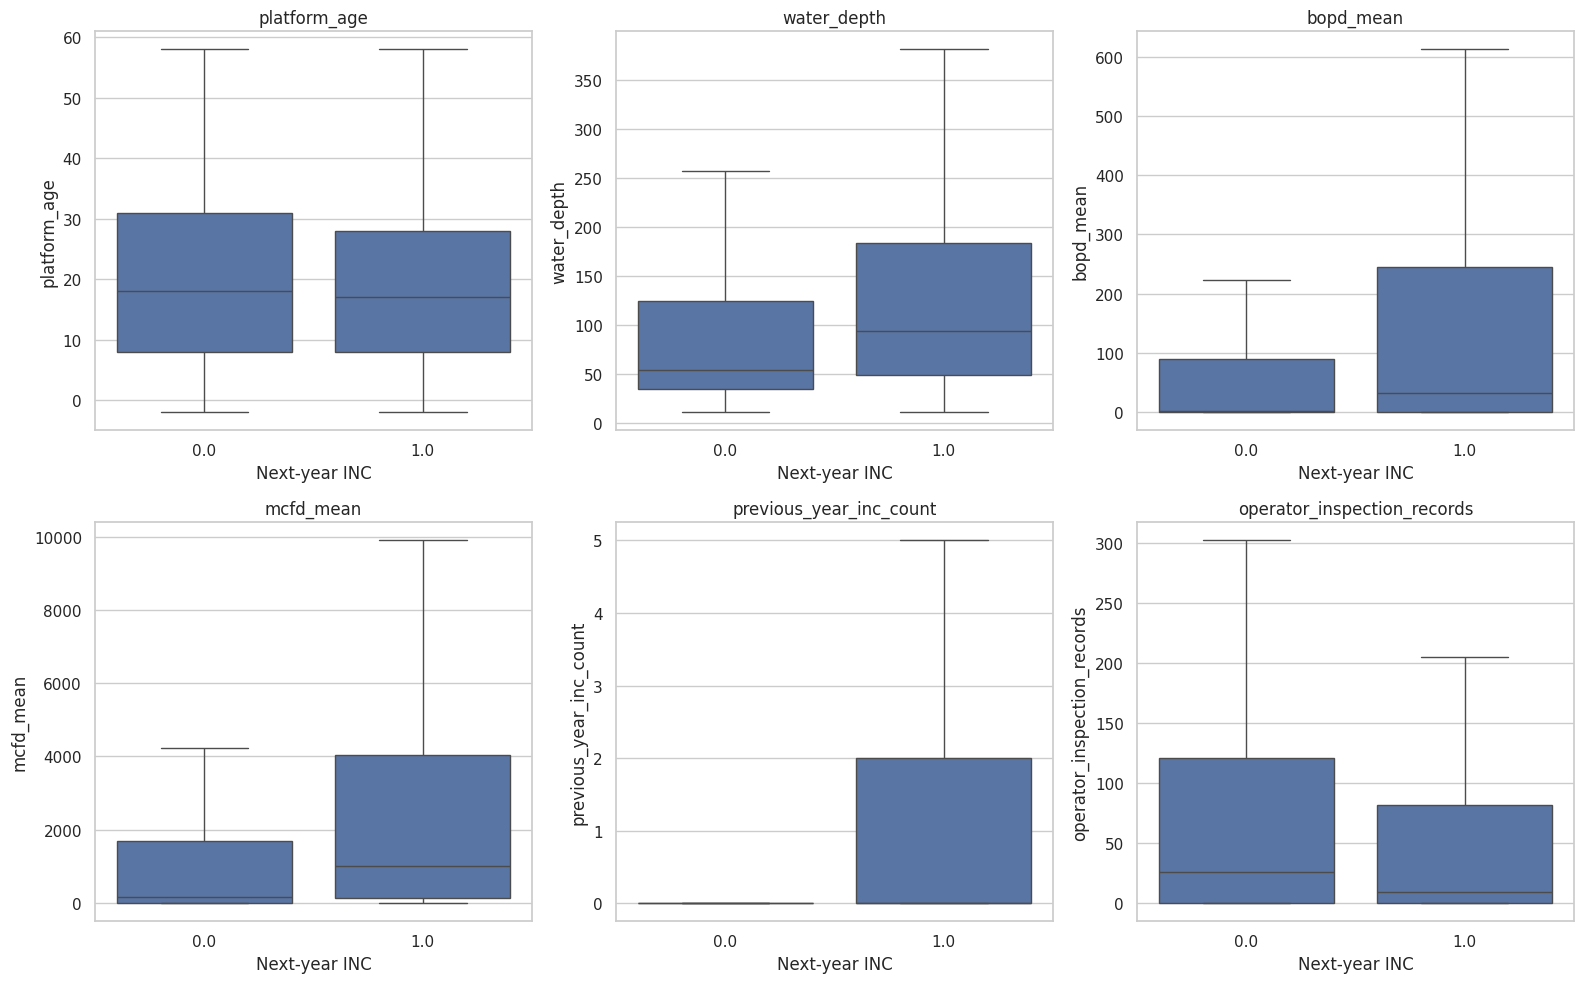

In [13]:
boxplot_features = [
    "platform_age",
    "water_depth",
    "bopd_mean",
    "mcfd_mean",
    "previous_year_inc_count",
    "operator_inspection_records",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

plot_sample = df_eda.sample(
    min(40_000, len(df_eda)),
    random_state=42,
)

for axis, column in zip(axes, boxplot_features):
    temporary = plot_sample[[TARGET, column]].copy()

    lower = temporary[column].quantile(0.01)
    upper = temporary[column].quantile(0.99)
    temporary[column] = temporary[column].clip(lower, upper)

    sns.boxplot(
        data=temporary,
        x=TARGET,
        y=column,
        showfliers=False,
        ax=axis,
    )

    axis.set_title(column)
    axis.set_xlabel("Next-year INC")
    axis.set_ylabel(column)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "04_target_boxplots.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [14]:
categorical_features = [
    "structure_type",
    "major_structure_flag",
    "district_code",
    "heliport_flag",
    "region_code",
    "attended_8hr_flag",
    "manned_24hr_flag",
]

categorical_results = []

for column in categorical_features:
    if column not in df_eda.columns:
        continue

    result = (
        df_eda.groupby(column, dropna=False)
        .agg(
            observations=(TARGET, "size"),
            positive_cases=(TARGET, "sum"),
            positive_rate=(TARGET, "mean"),
        )
        .reset_index()
    )

    # Avoid interpreting extremely small groups
    result = result[result["observations"] >= 100]
    result["variable"] = column
    categorical_results.append(result)

categorical_summary = pd.concat(
    categorical_results,
    ignore_index=True,
)

categorical_summary.to_csv(
    DATA_DIR / "eda_categorical_risk.csv",
    index=False,
)

display(
    categorical_summary.sort_values(
        ["variable", "positive_rate"],
        ascending=[True, False],
    )
)

,structure_type,observations,positive_cases,positive_rate,variable,major_structure_flag,district_code,heliport_flag,region_code,attended_8hr_flag,manned_24hr_flag
23,NaN,10370,3518.0,0.339248,attended_8hr_flag,NaN,NaN,NaN,NaN,Y,NaN
22,NaN,76345,18128.0,0.237448,attended_8hr_flag,NaN,NaN,NaN,NaN,N,NaN
24,NaN,1757,150.0,0.085373,attended_8hr_flag,NaN,NaN,NaN,NaN,NaN,NaN
14,NaN,9822,3144.0,0.320098,district_code,NaN,4.0,NaN,NaN,NaN,NaN
13,NaN,18677,5314.0,0.284521,district_code,NaN,3.0,NaN,NaN,NaN,NaN
15,NaN,18265,4499.0,0.246318,district_code,NaN,5.0,NaN,NaN,NaN,NaN
12,NaN,21936,5139.0,0.234272,district_code,NaN,2.0,NaN,NaN,NaN,NaN
11,NaN,18990,3700.0,0.194839,district_code,NaN,1.0,NaN,NaN,NaN,NaN
16,NaN,782,0.0,0.000000,district_code,NaN,NaN,NaN,NaN,NaN,NaN
18,NaN,49930,14634.0,0.293090,heliport_flag,NaN,NaN,Y,NaN,NaN,NaN


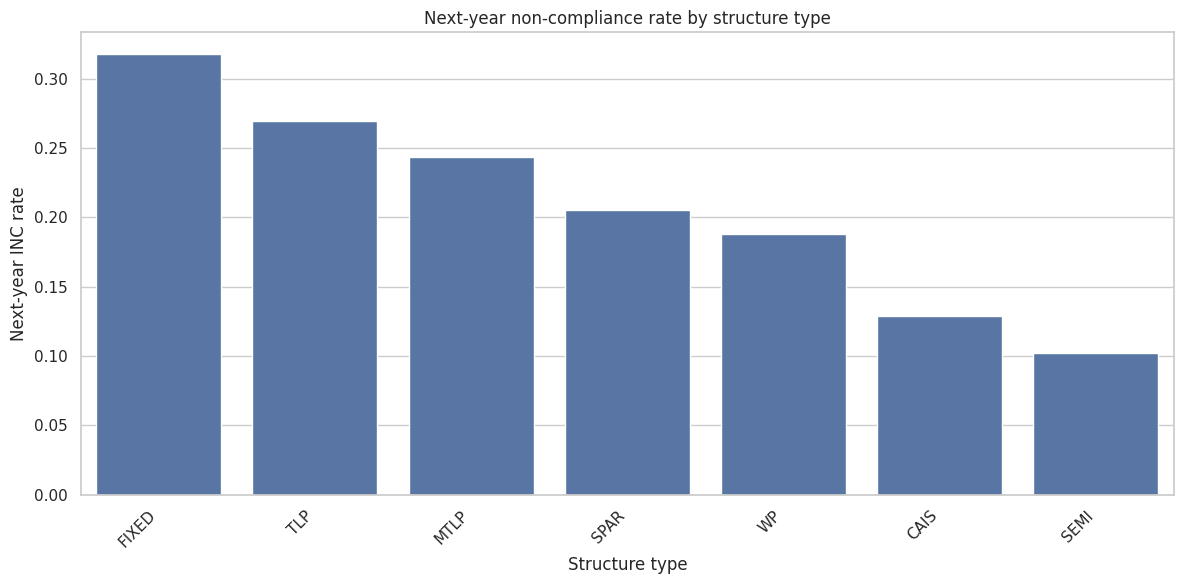

In [15]:
structure_risk = (
    categorical_summary[
        categorical_summary["variable"] == "structure_type"
    ]
    .sort_values("positive_rate", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=structure_risk,
    x="structure_type",
    y="positive_rate",
)

plt.ylabel("Next-year INC rate")
plt.xlabel("Structure type")
plt.title("Next-year non-compliance rate by structure type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_structure_type_risk.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

,target_correlation
inc_count_previous_3_observations,0.263268
enforcement_code_count,0.262638
any_inc,0.243562
inc_count,0.222459
previous_year_inc_count,0.208069
latitude,-0.149459
producing_wells_max,0.145387
producing_wells_mean,0.139927
year,-0.139614
years_until_removal,0.137817


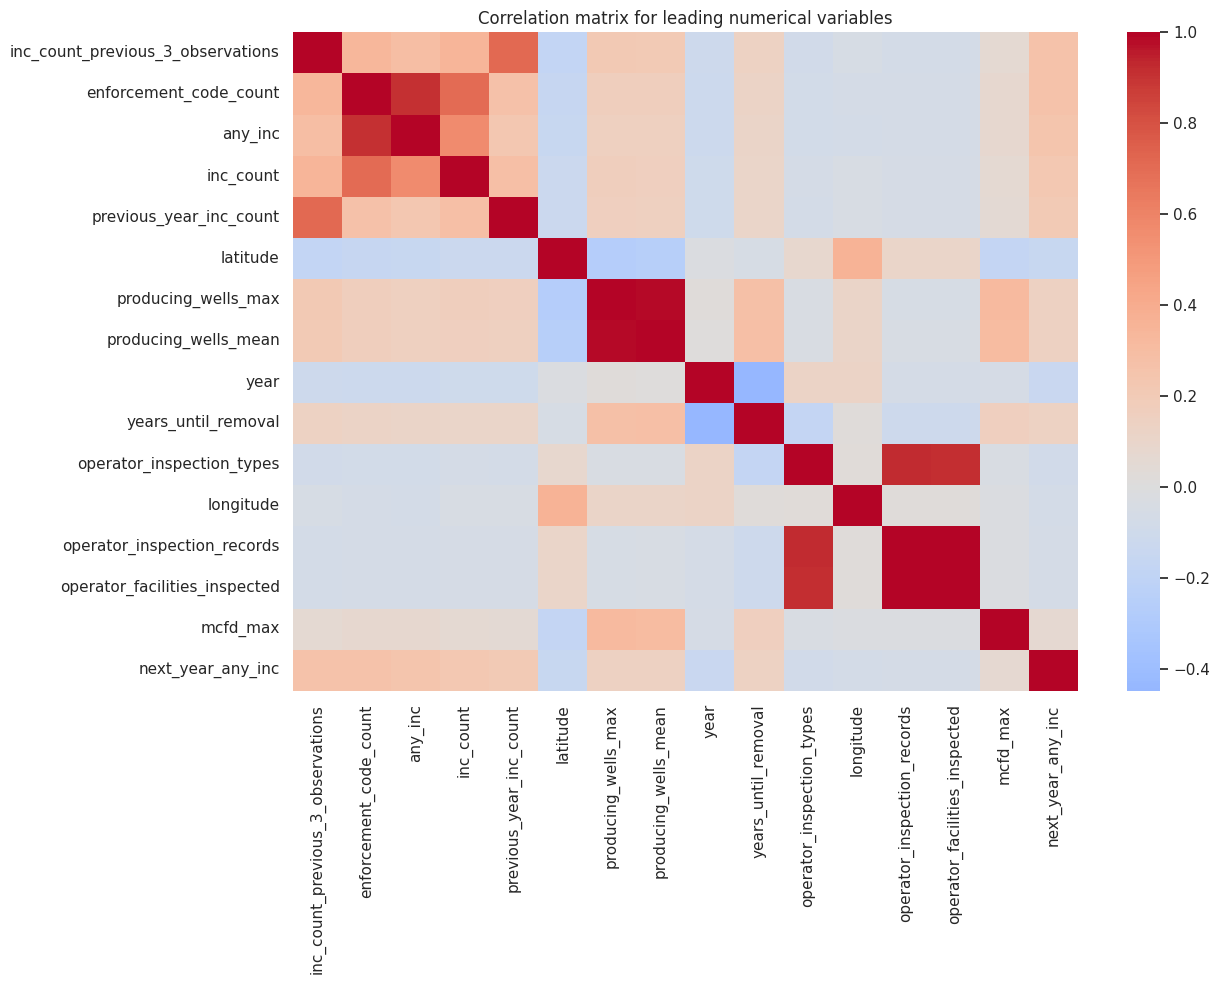

In [16]:
excluded_from_predictors = {
    "next_year_any_inc",
    "next_year_inc_count",
    "platform_id",
    "operator_name",
    "structure_name",
}

numeric_columns = (
    df_eda.select_dtypes(include=np.number)
    .columns
    .difference(list(excluded_from_predictors))
    .tolist()
)

correlations = (
    df_eda[numeric_columns + [TARGET]]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

display(correlations.to_frame("target_correlation").head(25))

correlations.to_csv(
    DATA_DIR / "eda_target_correlations.csv",
    header=["target_correlation"],
)

top_correlation_features = correlations.head(15).index.tolist()

correlation_matrix = (
    df_eda[top_correlation_features + [TARGET]]
    .corr(numeric_only=True)
)

plt.figure(figsize=(13, 10))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    square=False,
)
plt.title("Correlation matrix for leading numerical variables")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "06_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

,count,mean,std,min,25%,50%,75%,max
observed_years,5478.0,16.150,10.153,1.0,7.00,15.00,23.00,35.0
first_year,5478.0,1993.614,5.832,1990.0,1990.00,1990.00,1996.00,2023.0
last_year,5478.0,2008.824,10.209,1990.0,2001.00,2009.00,2017.00,2024.0
positive_years,5478.0,3.979,4.409,0.0,1.00,2.00,6.00,25.0
positive_rate,5478.0,0.230,0.209,0.0,0.05,0.19,0.36,1.0


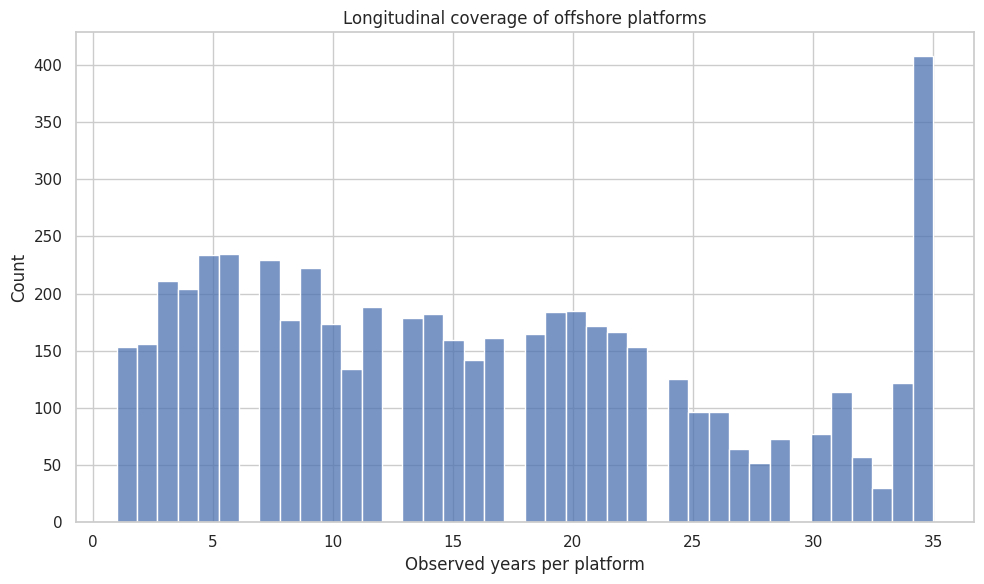

In [17]:
platform_summary = (
    df_eda.groupby("platform_id")
    .agg(
        observed_years=("year", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max"),
        positive_years=(TARGET, "sum"),
        positive_rate=(TARGET, "mean"),
    )
    .reset_index()
)

display(platform_summary.describe().T.round(3))

plt.figure(figsize=(10, 6))
sns.histplot(
    platform_summary["observed_years"],
    bins=40,
)
plt.xlabel("Observed years per platform")
plt.title("Longitudinal coverage of offshore platforms")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "07_platform_observation_length.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [18]:
# Recommended initial study period
analysis_df = df_eda[
    (df_eda["year"] >= 2000)
    & (df_eda["year"] <= 2024)
].copy()

train = analysis_df[
    analysis_df["year"] <= 2017
].copy()

validation = analysis_df[
    analysis_df["year"].between(2018, 2021)
].copy()

test = analysis_df[
    analysis_df["year"].between(2022, 2024)
].copy()

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "years": ["2000–2017", "2018–2021", "2022–2024"],
    "rows": [len(train), len(validation), len(test)],
    "platforms": [
        train["platform_id"].nunique(),
        validation["platform_id"].nunique(),
        test["platform_id"].nunique(),
    ],
    "positive_rate": [
        train[TARGET].mean(),
        validation[TARGET].mean(),
        test[TARGET].mean(),
    ],
})

display(split_summary.round(4))

train.to_csv(
    DATA_DIR / "train_temporal.csv.gz",
    index=False,
    compression="gzip",
)

validation.to_csv(
    DATA_DIR / "validation_temporal.csv.gz",
    index=False,
    compression="gzip",
)

test.to_csv(
    DATA_DIR / "test_temporal.csv.gz",
    index=False,
    compression="gzip",
)

,split,years,rows,platforms,positive_rate
0,Train,2000–2017,47276,4260,0.2453
1,Validation,2018–2021,4753,1362,0.0427
2,Test,2022–2024,2505,915,0.0399


In [19]:
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

EDA_ZIP = Path("/kaggle/working/bsee_eda_outputs.zip")

files_to_package = (
    list(FIGURE_DIR.glob("*.png"))
    + list(DATA_DIR.glob("eda_*.csv"))
    + [
        DATA_DIR / "train_temporal.csv.gz",
        DATA_DIR / "validation_temporal.csv.gz",
        DATA_DIR / "test_temporal.csv.gz",
    ]
)

with ZipFile(
    EDA_ZIP,
    mode="w",
    compression=ZIP_DEFLATED,
    compresslevel=9,
) as archive:
    for file_path in files_to_package:
        if file_path.exists():
            archive.write(file_path, arcname=file_path.name)

with ZipFile(EDA_ZIP, "r") as archive:
    corrupted_file = archive.testzip()
    if corrupted_file:
        raise RuntimeError(f"Corrupted archive member: {corrupted_file}")

print("EDA archive:", EDA_ZIP)
print(f"Size: {EDA_ZIP.stat().st_size / (1024**2):.2f} MB")

display(FileLink(str(EDA_ZIP)))

EDA archive: /kaggle/working/bsee_eda_outputs.zip
Size: 4.27 MB


/kaggle/working/bsee_eda_outputs.zip

In [20]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/kaggle/working/bsee_processed")
TARGET = "next_year_any_inc"

df = pd.read_csv(
    DATA_DIR / "bsee_platform_year_model.csv.gz",
    low_memory=False,
)

# Use a more internally consistent reporting period.
analysis_df = df[
    df["year"].between(2014, 2024)
].copy()

# Temporal split
train = analysis_df[
    df.loc[analysis_df.index, "year"].between(2014, 2019)
].copy()

validation = analysis_df[
    df.loc[analysis_df.index, "year"].between(2020, 2021)
].copy()

test = analysis_df[
    df.loc[analysis_df.index, "year"].between(2022, 2024)
].copy()

def describe_split(name, frame):
    return {
        "split": name,
        "year_start": int(frame["year"].min()),
        "year_end": int(frame["year"].max()),
        "rows": len(frame),
        "platforms": frame["platform_id"].nunique(),
        "positive_cases": int(frame[TARGET].sum()),
        "positive_rate": frame[TARGET].mean(),
    }

split_summary = pd.DataFrame([
    describe_split("Train", train),
    describe_split("Validation", validation),
    describe_split("Test", test),
])

display(split_summary.round(4))

train.to_csv(
    DATA_DIR / "train_2014_2019.csv.gz",
    index=False,
    compression="gzip",
)

validation.to_csv(
    DATA_DIR / "validation_2020_2021.csv.gz",
    index=False,
    compression="gzip",
)

test.to_csv(
    DATA_DIR / "test_2022_2024.csv.gz",
    index=False,
    compression="gzip",
)

,split,year_start,year_end,rows,platforms,positive_cases,positive_rate
0,Train,2014,2019,8856,1752,561,0.0633
1,Validation,2020,2021,2140,1157,92,0.0430
2,Test,2022,2024,2505,915,100,0.0399


In [3]:
"""Leakage audit and model preprocessing for the BSEE platform-year study.

Run in Kaggle after creating ``bsee_platform_year_model.csv.gz``:

    %run /kaggle/working/kaggle_feature_audit_preprocessing.py

The script creates two experimental datasets:

1. early_warning: excludes all current-year non-compliance/enforcement outcomes.
2. enhanced_supervision: includes current-year outcomes to predict next-year risk.

Every learned preprocessing parameter is fitted on 2014-2019 only. Validation
(2020-2021) and test (2022-2024) remain strictly out of fit operations.
"""

from __future__ import annotations

import json
import logging
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.utils.class_weight import compute_class_weight


LOG = logging.getLogger("bsee-feature-preprocessing")
TARGET = "next_year_any_inc"
RANDOM_STATE = 42

# These columns identify an observation or are retained for evaluation/grouping.
# They must never be passed to an ordinary predictive model as numeric values.
IDENTIFIER_COLUMNS = [
    "platform_id",
    "operator_id",
    "operator_name",
    "lease_number",
    "structure_name",
    "block_number",
]

# Future labels. These are prohibited predictors in every experiment.
TARGET_COLUMNS = [
    "next_year_any_inc",
    "next_year_inc_count",
]

# Retrospectively known or unsuitable raw fields.
EXCLUDED_COLUMNS = [
    "install_date",          # represented safely by platform_age
    "removal_date",          # may reveal future platform retirement
    "years_until_removal",   # directly uses a future removal date
    "operator_id_inc",       # source-specific identifier if present
]

# Current-year compliance/enforcement outcomes. Excluded from early warning,
# included in enhanced supervision because they are known by the end of year t.
CURRENT_YEAR_COMPLIANCE_COLUMNS = [
    "inc_count",
    "enforcement_code_count",
    "any_inc",
    "operator_warning_incs",
    "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

# Approved categorical predictors with manageable and meaningful cardinality.
CATEGORICAL_FEATURES = [
    "area_code",
    "region_code",
    "structure_type",
    "major_structure_flag",
    "district_code",
    "heliport_flag",
    "attended_8hr_flag",
    "manned_24hr_flag",
]

# Approved predictors available by the end of feature year t.
BASE_NUMERIC_FEATURES = [
    "active_months",
    "producing_wells_mean",
    "producing_wells_max",
    "bopd_mean",
    "bopd_max",
    "mcfd_mean",
    "mcfd_max",
    "boepd_mean",
    "bwpd_mean",
    "water_depth",
    "latitude",
    "longitude",
    "platform_age",
    "operator_facilities_inspected",
    "operator_inspection_records",
    "operator_inspection_types",
    "investigated_accident_count",
    "accident_type_count",
    "previous_year_inc_count",
    "inc_count_previous_3_observations",
    "previous_year_accident_count",
    "production_change_bopd",
    "production_change_mcfd",
]


class QuantileClipper(BaseEstimator, TransformerMixin):
    """Winsorize numerical columns using quantiles learned from training only."""

    def __init__(self, lower: float = 0.01, upper: float = 0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        array = np.asarray(X, dtype=float)
        self.n_features_in_ = array.shape[1]
        if hasattr(X, "columns"):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.lower_bounds_ = np.nanquantile(array, self.lower, axis=0)
        self.upper_bounds_ = np.nanquantile(array, self.upper, axis=0)
        return self

    def transform(self, X):
        array = np.asarray(X, dtype=float)
        return np.clip(array, self.lower_bounds_, self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        """Clipping changes values only, so feature names pass through unchanged."""
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        if hasattr(self, "feature_names_in_"):
            return self.feature_names_in_.copy()
        return np.asarray(
            [f"x{i}" for i in range(self.n_features_in_)], dtype=object
        )


def locate_model_file() -> Path:
    """Find compressed or uncompressed modelling data in Kaggle."""
    candidates = [
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/bsee-preprocessed-dataset/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/input/bsee-preprocessed-dataset/bsee_platform_year_model.csv"),
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate

    matches = list(Path("/kaggle/input").rglob("bsee_platform_year_model.csv.gz"))
    matches += list(Path("/kaggle/input").rglob("bsee_platform_year_model.csv"))
    if len(matches) == 1:
        return matches[0]
    if not matches:
        raise FileNotFoundError(
            "Could not find bsee_platform_year_model.csv(.gz) in /kaggle/working "
            "or /kaggle/input. Run the preprocessing pipeline first."
        )
    raise RuntimeError(f"Multiple modelling files found; keep one attached: {matches}")


def clean_model_frame(frame: pd.DataFrame) -> pd.DataFrame:
    """Apply deterministic cleaning that does not learn from future periods."""
    result = frame.copy()
    result[TARGET] = pd.to_numeric(result[TARGET], errors="coerce")
    result["year"] = pd.to_numeric(result["year"], errors="coerce")

    # Restrict the primary analysis to the stable reporting period.
    result = result[result["year"].between(2014, 2024)].copy()
    result = result[result[TARGET].isin([0, 1])].copy()
    result["year"] = result["year"].astype(int)
    result[TARGET] = result[TARGET].astype("int8")

    # pct_change can produce infinities when the previous value is zero.
    result.replace([np.inf, -np.inf], np.nan, inplace=True)

    # Use ordinary object strings plus np.nan for broad sklearn compatibility.
    for column in CATEGORICAL_FEATURES:
        if column in result.columns:
            result[column] = result[column].astype("string").astype(object)
            result[column] = result[column].where(result[column].notna(), np.nan)

    if result.duplicated(["platform_id", "year"]).any():
        raise ValueError("Duplicate platform-year observations detected")
    return result


def temporal_split(frame: pd.DataFrame):
    train = frame[frame["year"].between(2014, 2019)].copy()
    validation = frame[frame["year"].between(2020, 2021)].copy()
    test = frame[frame["year"].between(2022, 2024)].copy()

    if min(len(train), len(validation), len(test)) == 0:
        raise ValueError("At least one temporal split is empty")
    return train, validation, test


def available(columns: list[str], frame: pd.DataFrame) -> list[str]:
    """Keep declared columns that exist and report schema differences."""
    present = [column for column in columns if column in frame.columns]
    missing = sorted(set(columns) - set(present))
    if missing:
        LOG.warning("Declared columns absent from dataset: %s", missing)
    return present


def feature_sets(frame: pd.DataFrame) -> dict[str, dict[str, list[str]]]:
    categorical = available(CATEGORICAL_FEATURES, frame)
    base_numeric = available(BASE_NUMERIC_FEATURES, frame)
    compliance = available(CURRENT_YEAR_COMPLIANCE_COLUMNS, frame)

    return {
        "early_warning": {
            "numeric": base_numeric,
            "categorical": categorical,
        },
        "enhanced_supervision": {
            "numeric": base_numeric + compliance,
            "categorical": categorical,
        },
    }


def audit_features(frame: pd.DataFrame, sets: dict) -> pd.DataFrame:
    all_columns = set(frame.columns)
    early = set(sets["early_warning"]["numeric"] + sets["early_warning"]["categorical"])
    enhanced = set(
        sets["enhanced_supervision"]["numeric"]
        + sets["enhanced_supervision"]["categorical"]
    )

    rows = []
    for column in sorted(all_columns):
        if column in TARGET_COLUMNS:
            role = "target_prohibited"
        elif column in IDENTIFIER_COLUMNS:
            role = "identifier_grouping_only"
        elif column in EXCLUDED_COLUMNS:
            role = "excluded_future_or_redundant"
        elif column in CURRENT_YEAR_COMPLIANCE_COLUMNS:
            role = "enhanced_only_current_compliance"
        elif column == "year":
            role = "split_and_drift_analysis_only"
        elif column in early:
            role = "approved_both_models"
        elif column in enhanced:
            role = "approved_enhanced_model"
        else:
            role = "excluded_unapproved"

        rows.append(
            {
                "feature": column,
                "role": role,
                "dtype": str(frame[column].dtype),
                "missing_percent": round(float(frame[column].isna().mean() * 100), 3),
                "unique_values": int(frame[column].nunique(dropna=True)),
            }
        )
    return pd.DataFrame(rows)


def build_preprocessor(numeric: list[str], categorical: list[str]) -> ColumnTransformer:
    numeric_pipeline = Pipeline(
        steps=[
            ("clip", QuantileClipper(lower=0.01, upper=0.99)),
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", RobustScaler()),
        ]
    )

    categorical_pipeline = Pipeline(
        steps=[
            ("impute", SimpleImputer(strategy="most_frequent")),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=10,
                    sparse_output=True,
                ),
            ),
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric),
            ("categorical", categorical_pipeline, categorical),
        ],
        remainder="drop",
        sparse_threshold=0.3,
        verbose_feature_names_out=False,
    )


def save_split_metadata(frame: pd.DataFrame, path: Path) -> None:
    columns = [
        column
        for column in ["platform_id", "operator_id", "year", TARGET]
        if column in frame.columns
    ]
    frame[columns].to_csv(path, index=False)


def process_experiment(
    name: str,
    specification: dict[str, list[str]],
    train: pd.DataFrame,
    validation: pd.DataFrame,
    test: pd.DataFrame,
    output_root: Path,
) -> dict:
    experiment_dir = output_root / name
    experiment_dir.mkdir(parents=True, exist_ok=True)

    numeric = specification["numeric"]
    categorical = specification["categorical"]
    features = numeric + categorical

    X_train_raw = train[features]
    X_validation_raw = validation[features]
    X_test_raw = test[features]
    y_train = train[TARGET].to_numpy(dtype=np.int8)
    y_validation = validation[TARGET].to_numpy(dtype=np.int8)
    y_test = test[TARGET].to_numpy(dtype=np.int8)

    preprocessor = build_preprocessor(numeric, categorical)
    LOG.info("Fitting %s preprocessor on training data only", name)
    X_train = preprocessor.fit_transform(X_train_raw, y_train)
    X_validation = preprocessor.transform(X_validation_raw)
    X_test = preprocessor.transform(X_test_raw)

    # Use CSR consistently for efficient storage and downstream classifiers.
    X_train = sparse.csr_matrix(X_train)
    X_validation = sparse.csr_matrix(X_validation)
    X_test = sparse.csr_matrix(X_test)

    feature_names = preprocessor.get_feature_names_out().tolist()
    if X_train.shape[1] != len(feature_names):
        raise RuntimeError("Feature-name count does not match transformed matrix")

    sparse.save_npz(experiment_dir / "X_train.npz", X_train)
    sparse.save_npz(experiment_dir / "X_validation.npz", X_validation)
    sparse.save_npz(experiment_dir / "X_test.npz", X_test)
    np.save(experiment_dir / "y_train.npy", y_train)
    np.save(experiment_dir / "y_validation.npy", y_validation)
    np.save(experiment_dir / "y_test.npy", y_test)
    joblib.dump(preprocessor, experiment_dir / "preprocessor.joblib")

    (experiment_dir / "feature_names.json").write_text(
        json.dumps(feature_names, indent=2), encoding="utf-8"
    )
    (experiment_dir / "input_feature_specification.json").write_text(
        json.dumps(specification, indent=2), encoding="utf-8"
    )
    save_split_metadata(train, experiment_dir / "train_metadata.csv")
    save_split_metadata(validation, experiment_dir / "validation_metadata.csv")
    save_split_metadata(test, experiment_dir / "test_metadata.csv")

    classes = np.array([0, 1])
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
    class_weights = {str(int(cls)): float(weight) for cls, weight in zip(classes, weights)}
    scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

    summary = {
        "experiment": name,
        "input_numeric_features": len(numeric),
        "input_categorical_features": len(categorical),
        "transformed_features": int(X_train.shape[1]),
        "train_shape": list(X_train.shape),
        "validation_shape": list(X_validation.shape),
        "test_shape": list(X_test.shape),
        "train_positive_rate": float(y_train.mean()),
        "validation_positive_rate": float(y_validation.mean()),
        "test_positive_rate": float(y_test.mean()),
        "class_weights": class_weights,
        "scale_pos_weight": scale_pos_weight,
    }
    (experiment_dir / "preprocessing_summary.json").write_text(
        json.dumps(summary, indent=2), encoding="utf-8"
    )
    return summary


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
    model_path = locate_model_file()
    output_root = Path("/kaggle/working/bsee_model_inputs")
    output_root.mkdir(parents=True, exist_ok=True)

    LOG.info("Reading %s", model_path)
    frame = pd.read_csv(model_path, low_memory=False)
    frame = clean_model_frame(frame)
    train, validation, test = temporal_split(frame)
    sets = feature_sets(frame)

    audit = audit_features(frame, sets)
    audit.to_csv(output_root / "feature_leakage_audit.csv", index=False)
    (output_root / "approved_feature_sets.json").write_text(
        json.dumps(sets, indent=2), encoding="utf-8"
    )

    split_summary = pd.DataFrame(
        [
            {
                "split": name,
                "year_start": int(part["year"].min()),
                "year_end": int(part["year"].max()),
                "rows": int(len(part)),
                "platforms": int(part["platform_id"].nunique()),
                "positive_cases": int(part[TARGET].sum()),
                "positive_rate": float(part[TARGET].mean()),
            }
            for name, part in [
                ("train", train),
                ("validation", validation),
                ("test", test),
            ]
        ]
    )
    split_summary.to_csv(output_root / "temporal_split_summary.csv", index=False)

    summaries = []
    for name, specification in sets.items():
        summaries.append(
            process_experiment(
                name,
                specification,
                train,
                validation,
                test,
                output_root,
            )
        )

    (output_root / "all_preprocessing_summaries.json").write_text(
        json.dumps(summaries, indent=2), encoding="utf-8"
    )

    print("\nFeature leakage audit")
    print(audit.groupby("role").size().to_string())
    print("\nTemporal splits")
    print(split_summary.to_string(index=False))
    print("\nExperiment summaries")
    print(json.dumps(summaries, indent=2))
    print(f"\nOutputs written to: {output_root}")


if __name__ == "__main__":
    main()


INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
INFO Fitting early_warning preprocessor on training data only
INFO Fitting enhanced_supervision preprocessor on training data only



Feature leakage audit
role
approved_both_models                31
enhanced_only_current_compliance     6
excluded_future_or_redundant         3
identifier_grouping_only             6
split_and_drift_analysis_only        1
target_prohibited                    2

Temporal splits
     split  year_start  year_end  rows  platforms  positive_cases  positive_rate
     train        2014      2019  8856       1752             561       0.063347
validation        2020      2021  2140       1157              92       0.042991
      test        2022      2024  2505        915             100       0.039920

Experiment summaries
[
  {
    "experiment": "early_warning",
    "input_numeric_features": 23,
    "input_categorical_features": 8,
    "transformed_features": 90,
    "train_shape": [
      8856,
      90
    ],
    "validation_shape": [
      2140,
      90
    ],
    "test_shape": [
      2505,
      90
    ],
    "train_positive_rate": 0.06334688346883469,
    "validation_positive_rate": 

In [4]:
from pathlib import Path
import shutil

INPUT_DIR = Path("/kaggle/working/bsee_model_inputs")
ZIP_BASE = Path("/kaggle/working/bsee_model_inputs")

if not INPUT_DIR.exists():
    raise FileNotFoundError(
        f"Model-input directory not found: {INPUT_DIR}. "
        "Run the preprocessing pipeline first."
    )

zip_path = Path(
    shutil.make_archive(
        base_name=str(ZIP_BASE),
        format="zip",
        root_dir=str(INPUT_DIR.parent),
        base_dir=INPUT_DIR.name,
    )
)

size_mb = zip_path.stat().st_size / (1024**2)

print("ZIP created successfully")
print("File:", zip_path)
print(f"Size: {size_mb:.2f} MB")

ZIP created successfully
File: /kaggle/working/bsee_model_inputs.zip
Size: 1.63 MB


In [6]:
"""Advanced BSEE platform-risk modelling on Kaggle.

Models: LightGBM, CatBoost, TabNet, and a PyTorch FT-style Transformer.
Protocol: tune on 2020-2021 validation PR-AUC, select the validation F1
threshold, refit five seeds on the unchanged training set, and report the
untouched 2022-2024 test set.  No test observation is used for selection.
"""

from __future__ import annotations

import gc
import json
import logging
import math
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore", category=UserWarning)
LOG = logging.getLogger("bsee_advanced_models")

# --------------------------- user controls ---------------------------
SEEDS = [11, 22, 33, 44, 55]
TUNING_SEED = 2026
N_TRIALS = 12                 # Increase to 25-50 for the final paper run.
NEURAL_EPOCHS = 120
NEURAL_PATIENCE = 15
EXPERIMENTS = ["early_warning", "enhanced_supervision"]
MODELS = ["lightgbm", "catboost", "tabnet", "ft_transformer"]
INPUT_ROOT = Path("/kaggle/working/bsee_model_inputs")
OUTPUT_ROOT = Path("/kaggle/working/bsee_advanced_results")


def ensure_packages() -> None:
    """Install only packages missing from the Kaggle image."""
    required = {
        "lightgbm": "lightgbm",
        "catboost": "catboost",
        "optuna": "optuna",
        "pytorch_tabnet": "pytorch-tabnet",
    }
    missing = []
    for module, package in required.items():
        try:
            __import__(module)
        except ImportError:
            missing.append(package)
    if missing:
        LOG.info("Installing missing packages: %s", ", ".join(missing))
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", *missing]
        )


ensure_packages()
import lightgbm as lgb  # noqa: E402
import optuna  # noqa: E402
import torch  # noqa: E402
from catboost import CatBoostClassifier  # noqa: E402
from pytorch_tabnet.tab_model import TabNetClassifier  # noqa: E402
from torch import nn  # noqa: E402
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402

optuna.logging.set_verbosity(optuna.logging.WARNING)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_input_root() -> Path:
    if (INPUT_ROOT / "early_warning" / "X_train.npz").exists():
        return INPUT_ROOT

    # The files may be nested differently after a Kaggle dataset upload or
    # archive extraction, so search both writable output and attached inputs.
    matches = []
    for search_root in [Path("/kaggle/working"), Path("/kaggle/input")]:
        if search_root.exists():
            matches.extend(
                path
                for path in search_root.rglob("X_train.npz")
                if path.parent.name.lower() == "early_warning"
            )

    # If only the generated ZIP remains, recover it automatically.
    if not matches:
        zip_candidates = [Path("/kaggle/working/bsee_model_inputs.zip")]
        zip_candidates.extend(Path("/kaggle/input").rglob("bsee_model_inputs.zip"))
        for zip_path in zip_candidates:
            if zip_path.exists():
                extraction_root = Path("/kaggle/working/bsee_model_inputs_extracted")
                extraction_root.mkdir(parents=True, exist_ok=True)
                LOG.info("Extracting model inputs from %s", zip_path)
                with zipfile.ZipFile(zip_path) as archive:
                    archive.extractall(extraction_root)
                matches.extend(
                    path
                    for path in extraction_root.rglob("X_train.npz")
                    if path.parent.name.lower() == "early_warning"
                )
                if matches:
                    break

    if not matches:
        raise FileNotFoundError(
            "Could not locate bsee_model_inputs. Run the feature-audit "
            "preprocessing notebook first or attach its output as a dataset."
        )
    return matches[0].parent.parent


def load_experiment(root: Path, name: str) -> dict:
    folder = root / name
    data = {
        "X_train": sparse.load_npz(folder / "X_train.npz").astype(np.float32),
        "X_val": sparse.load_npz(folder / "X_validation.npz").astype(np.float32),
        "X_test": sparse.load_npz(folder / "X_test.npz").astype(np.float32),
        "y_train": np.load(folder / "y_train.npy").astype(np.int64),
        "y_val": np.load(folder / "y_validation.npy").astype(np.int64),
        "y_test": np.load(folder / "y_test.npy").astype(np.int64),
        "meta_val": pd.read_csv(folder / "validation_metadata.csv"),
        "meta_test": pd.read_csv(folder / "test_metadata.csv"),
    }
    data["scale_pos_weight"] = float(
        (data["y_train"] == 0).sum() / (data["y_train"] == 1).sum()
    )
    return data


def safe_pr_auc(y: np.ndarray, probability: np.ndarray) -> float:
    return float(average_precision_score(y, probability))


def select_f1_threshold(y: np.ndarray, probability: np.ndarray) -> tuple[float, float]:
    """Select threshold on validation only using exact prediction breakpoints."""
    candidates = np.unique(np.clip(probability, 1e-6, 1 - 1e-6))
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = np.array([f1_score(y, probability >= t, zero_division=0) for t in candidates])
    index = int(np.argmax(scores))
    return float(candidates[index]), float(scores[index])


def metrics(y: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {
        "pr_auc": safe_pr_auc(y, probability),
        "roc_auc": float(roc_auc_score(y, probability)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "brier_score": float(brier_score_loss(y, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


# ------------------------ classical advanced models ------------------------
def suggest_lgbm(trial: optuna.Trial) -> dict:
    return {
        "n_estimators": 3000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 12, 96),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 180),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.55, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 20.0, log=True),
    }


def fit_lgbm(params: dict, data: dict, seed: int):
    model = lgb.LGBMClassifier(
        objective="binary", random_state=seed, n_jobs=-1,
        scale_pos_weight=data["scale_pos_weight"], verbosity=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=[(data["X_val"], data["y_val"])],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return model


def suggest_catboost(trial: optuna.Trial) -> dict:
    return {
        "iterations": 2500,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.10, log=True),
        "depth": trial.suggest_int("depth", 4, 9),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 2.0),
    }


def fit_catboost(params: dict, data: dict, seed: int):
    model = CatBoostClassifier(
        loss_function="Logloss", eval_metric="PRAUC", random_seed=seed,
        auto_class_weights="Balanced", verbose=False, allow_writing_files=False,
        thread_count=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=(data["X_val"], data["y_val"]),
        early_stopping_rounds=100, verbose=False,
    )
    return model


# ------------------------------ TabNet ------------------------------
def suggest_tabnet(trial: optuna.Trial) -> dict:
    width = trial.suggest_categorical("width", [8, 16, 24, 32])
    return {
        "n_d": width, "n_a": width,
        "n_steps": trial.suggest_int("n_steps", 3, 6),
        "gamma": trial.suggest_float("gamma", 1.1, 1.8),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-6, 1e-3, log=True),
        "mask_type": trial.suggest_categorical("mask_type", ["sparsemax", "entmax"]),
        "lr": trial.suggest_float("lr", 5e-4, 3e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024]),
    }


def fit_tabnet(params: dict, data: dict, seed: int):
    Xtr = data["X_train"].toarray().astype(np.float32)
    Xva = data["X_val"].toarray().astype(np.float32)
    p = dict(params)
    lr, batch_size = p.pop("lr"), p.pop("batch_size")
    model = TabNetClassifier(
        seed=seed, optimizer_fn=torch.optim.AdamW,
        optimizer_params={"lr": lr, "weight_decay": 1e-5},
        scheduler_fn=torch.optim.lr_scheduler.ReduceLROnPlateau,
        scheduler_params={"mode": "max", "factor": 0.5, "patience": 5},
        verbose=0, device_name="auto", **p,
    )
    # Weighted loss without resampling.
    class_weights = {0: 1.0, 1: data["scale_pos_weight"]}
    model.fit(
        Xtr, data["y_train"], eval_set=[(Xva, data["y_val"])],
        eval_name=["validation"], eval_metric=["auc"],
        weights=class_weights, max_epochs=NEURAL_EPOCHS,
        patience=NEURAL_PATIENCE, batch_size=batch_size,
        virtual_batch_size=min(128, batch_size), num_workers=0,
        drop_last=False,
    )
    return model


# -------------------------- FT-style Transformer --------------------------
class FTTransformer(nn.Module):
    """Tokenizes every transformed scalar feature and applies self-attention."""

    def __init__(self, n_features: int, d_token: int, n_heads: int,
                 n_layers: int, dropout: float, ff_factor: int):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_token))
        self.bias = nn.Parameter(torch.empty(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        nn.init.xavier_uniform_(self.weight)
        nn.init.zeros_(self.bias)
        layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * ff_factor,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, n_layers)
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Linear(d_token, 1)

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(self.norm(encoded[:, 0])).squeeze(1)


def suggest_ft(trial: optuna.Trial) -> dict:
    d_token = trial.suggest_categorical("d_token", [24, 32, 48, 64])
    valid_heads = [h for h in [2, 4, 8] if d_token % h == 0]
    return {
        "d_token": d_token,
        "n_heads": trial.suggest_categorical("n_heads", valid_heads),
        "n_layers": trial.suggest_int("n_layers", 2, 4),
        "dropout": trial.suggest_float("dropout", 0.05, 0.35),
        "ff_factor": trial.suggest_categorical("ff_factor", [2, 3, 4]),
        "lr": trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


class TorchWrapper:
    def __init__(self, model: nn.Module, device: torch.device, batch_size: int):
        self.model, self.device, self.batch_size = model, device, batch_size

    def predict_proba(self, X):
        array = X.toarray().astype(np.float32) if sparse.issparse(X) else np.asarray(X, np.float32)
        loader = DataLoader(TensorDataset(torch.from_numpy(array)), batch_size=self.batch_size)
        output = []
        self.model.eval()
        with torch.no_grad():
            for (xb,) in loader:
                output.append(torch.sigmoid(self.model(xb.to(self.device))).cpu().numpy())
        p = np.concatenate(output)
        return np.column_stack([1 - p, p])


def fit_ft(params: dict, data: dict, seed: int):
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    Xtr = torch.from_numpy(data["X_train"].toarray().astype(np.float32))
    ytr = torch.from_numpy(data["y_train"].astype(np.float32))
    Xva = data["X_val"]
    p = dict(params)
    lr, wd, batch_size = p.pop("lr"), p.pop("weight_decay"), p.pop("batch_size")
    model = FTTransformer(Xtr.shape[1], **p).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(data["scale_pos_weight"], device=device)
    )
    loader = DataLoader(
        TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    best_score, best_state, bad_epochs = -np.inf, None, 0
    wrapper = TorchWrapper(model, device, batch_size)
    for _epoch in range(NEURAL_EPOCHS):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb.to(device)), yb.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        score = safe_pr_auc(data["y_val"], wrapper.predict_proba(Xva)[:, 1])
        if score > best_score + 1e-5:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= NEURAL_PATIENCE:
                break
    model.load_state_dict(best_state)
    return wrapper


SUGGESTERS = {
    "lightgbm": suggest_lgbm, "catboost": suggest_catboost,
    "tabnet": suggest_tabnet, "ft_transformer": suggest_ft,
}
FITTERS = {
    "lightgbm": fit_lgbm, "catboost": fit_catboost,
    "tabnet": fit_tabnet, "ft_transformer": fit_ft,
}


def positive_probability(model, model_name: str, X) -> np.ndarray:
    if model_name == "tabnet":
        X = X.toarray().astype(np.float32)
    return np.asarray(model.predict_proba(X)[:, 1], dtype=float)


def tune_model(model_name: str, data: dict, experiment: str) -> tuple[dict, pd.DataFrame]:
    def objective(trial: optuna.Trial) -> float:
        params = SUGGESTERS[model_name](trial)
        try:
            model = FITTERS[model_name](params, data, TUNING_SEED)
            probability = positive_probability(model, model_name, data["X_val"])
            score = safe_pr_auc(data["y_val"], probability)
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            return score
        except Exception as error:
            LOG.exception("Trial failed for %s/%s: %s", experiment, model_name, error)
            return 0.0

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    trials = study.trials_dataframe()
    return SUGGESTERS[model_name](optuna.trial.FixedTrial(study.best_params)), trials


def save_model(model, model_name: str, path: Path) -> None:
    if model_name == "lightgbm":
        model.booster_.save_model(str(path.with_suffix(".txt")))
    elif model_name == "catboost":
        model.save_model(str(path.with_suffix(".cbm")))
    elif model_name == "tabnet":
        model.save_model(str(path))
    else:
        torch.save(model.model.state_dict(), path.with_suffix(".pt"))


def run_model(experiment: str, model_name: str, data: dict, output: Path) -> list[dict]:
    model_dir = output / experiment / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    LOG.info("Tuning %s / %s (%d trials)", experiment, model_name, N_TRIALS)
    best_params, trials = tune_model(model_name, data, experiment)
    trials.to_csv(model_dir / "optuna_trials.csv", index=False)
    (model_dir / "best_params.json").write_text(
        json.dumps(best_params, indent=2), encoding="utf-8"
    )

    rows = []
    for seed in SEEDS:
        LOG.info("Final fit %s / %s / seed %d", experiment, model_name, seed)
        started = time.time()
        model = FITTERS[model_name](best_params, data, seed)
        val_p = positive_probability(model, model_name, data["X_val"])
        test_p = positive_probability(model, model_name, data["X_test"])
        threshold, _ = select_f1_threshold(data["y_val"], val_p)

        for split, y, probability in [
            ("validation", data["y_val"], val_p),
            ("test", data["y_test"], test_p),
        ]:
            row = {
                "experiment": experiment, "model": model_name,
                "seed": seed, "split": split,
                "runtime_seconds": float(time.time() - started),
                **metrics(y, probability, threshold),
            }
            rows.append(row)

        prediction_frame = data["meta_test"].copy()
        prediction_frame["probability"] = test_p
        prediction_frame["threshold"] = threshold
        prediction_frame["prediction"] = (test_p >= threshold).astype(np.int8)
        prediction_frame.to_csv(model_dir / f"test_predictions_seed_{seed}.csv", index=False)
        save_model(model, model_name, model_dir / f"model_seed_{seed}")
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return rows


def aggregate_results(results: pd.DataFrame) -> pd.DataFrame:
    metric_columns = [
        "pr_auc", "roc_auc", "f1", "precision", "recall",
        "balanced_accuracy", "brier_score", "threshold", "runtime_seconds",
    ]
    grouped = results.groupby(["experiment", "model", "split"])[metric_columns]
    mean = grouped.mean().add_suffix("_mean")
    std = grouped.std(ddof=1).add_suffix("_std")
    return mean.join(std).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_everything(TUNING_SEED)
    input_root = locate_input_root()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Model inputs: %s", input_root)
    LOG.info("Results: %s", OUTPUT_ROOT)

    all_rows = []
    for experiment in EXPERIMENTS:
        data = load_experiment(input_root, experiment)
        for model_name in MODELS:
            all_rows.extend(run_model(experiment, model_name, data, OUTPUT_ROOT))

    results = pd.DataFrame(all_rows)
    summary = aggregate_results(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "seeds": SEEDS, "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "neural_epochs": NEURAL_EPOCHS, "neural_patience": NEURAL_PATIENCE,
        "selection_metric": "validation_pr_auc",
        "threshold_rule": "maximum validation F1",
        "test_use": "final evaluation only",
    }
    (OUTPUT_ROOT / "run_configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_advanced_results",
        "zip",
        root_dir=str(OUTPUT_ROOT.parent),
        base_dir=OUTPUT_ROOT.name,
    )
    print("\nFive-seed results (mean ± standard deviation)")
    print(summary.to_string(index=False))
    print(f"\nOutputs written to: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


FileNotFoundError: Could not locate bsee_model_inputs. Run the feature-audit preprocessing notebook first or attach its output as a dataset.

In [3]:
"""Advanced BSEE platform-risk modelling on Kaggle.

Models: LightGBM, CatBoost, TabNet, and a PyTorch FT-style Transformer.
Protocol: tune on 2020-2021 validation PR-AUC, select the validation F1
threshold, refit five seeds on the unchanged training set, and report the
untouched 2022-2024 test set.  No test observation is used for selection.
"""

from __future__ import annotations

import gc
import json
import logging
import math
import os
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

warnings.filterwarnings("ignore", category=UserWarning)
LOG = logging.getLogger("bsee_advanced_models")

# --------------------------- user controls ---------------------------
SEEDS = [11, 22, 33, 44, 55]
TUNING_SEED = 2026
N_TRIALS = 12                 # Increase to 25-50 for the final paper run.
NEURAL_EPOCHS = 120
NEURAL_PATIENCE = 15
EXPERIMENTS = ["early_warning", "enhanced_supervision"]
MODELS = ["lightgbm", "catboost", "tabnet", "ft_transformer"]
INPUT_ROOT = Path("/kaggle/working/bsee_model_inputs")
OUTPUT_ROOT = Path("/kaggle/working/bsee_advanced_results")


def ensure_packages() -> None:
    """Install only packages missing from the Kaggle image."""
    required = {
        "lightgbm": "lightgbm",
        "catboost": "catboost",
        "optuna": "optuna",
        "pytorch_tabnet": "pytorch-tabnet",
    }
    missing = []
    for module, package in required.items():
        try:
            __import__(module)
        except ImportError:
            missing.append(package)
    if missing:
        LOG.info("Installing missing packages: %s", ", ".join(missing))
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", *missing]
        )


ensure_packages()
import lightgbm as lgb  # noqa: E402
import optuna  # noqa: E402
import torch  # noqa: E402
from catboost import CatBoostClassifier  # noqa: E402
from pytorch_tabnet.tab_model import TabNetClassifier  # noqa: E402
from torch import nn  # noqa: E402
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402

optuna.logging.set_verbosity(optuna.logging.WARNING)


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_input_root() -> Path:
    """Find and validate the uploaded bsee_model_inputs directory."""
    direct_candidates = [
        Path("/kaggle/working/bsee_model_inputs"),
        Path("/kaggle/input/bsee-model/bsee_model_inputs"),
        Path("/kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs"),
    ]

    # os.walk is reliable across both standard Kaggle mounts and the newer
    # /kaggle/input/datasets/<owner>/<slug> layout.
    discovered = []
    for search_root in ["/kaggle/input", "/kaggle/working"]:
        if not os.path.isdir(search_root):
            continue
        for directory, subdirectories, _files in os.walk(search_root):
            if os.path.basename(directory).lower() == "bsee_model_inputs":
                discovered.append(Path(directory))
                subdirectories[:] = []

    candidates = direct_candidates + discovered
    seen = set()
    candidates = [p for p in candidates if not (str(p) in seen or seen.add(str(p)))]

    required_relative = [
        Path(experiment) / filename
        for experiment in EXPERIMENTS
        for filename in [
            "X_train.npz", "X_validation.npz", "X_test.npz",
            "y_train.npy", "y_validation.npy", "y_test.npy",
            "validation_metadata.csv", "test_metadata.csv",
        ]
    ]

    diagnostics = []
    for candidate in candidates:
        if not candidate.is_dir():
            continue
        missing = [str(rel) for rel in required_relative if not (candidate / rel).is_file()]
        diagnostics.append((candidate, missing))
        if not missing:
            return candidate

    # Recover an attached/output ZIP if no complete directory was found.
    zip_candidates = [Path("/kaggle/working/bsee_model_inputs.zip")]
    for search_root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if search_root.exists():
            zip_candidates.extend(search_root.rglob("bsee_model_inputs.zip"))
    for zip_path in zip_candidates:
        if not zip_path.is_file():
            continue
        extraction_root = Path("/kaggle/working/bsee_model_inputs_recovered")
        extraction_root.mkdir(parents=True, exist_ok=True)
        LOG.info("Extracting %s", zip_path)
        with zipfile.ZipFile(zip_path) as archive:
            archive.extractall(extraction_root)
        for directory, _subdirectories, _files in os.walk(extraction_root):
            candidate = Path(directory)
            if candidate.name.lower() != "bsee_model_inputs":
                continue
            missing = [rel for rel in required_relative if not (candidate / rel).is_file()]
            if not missing:
                return candidate

    message = ["No complete bsee_model_inputs directory was found."]
    for candidate, missing in diagnostics:
        message.append(f"\nFound directory: {candidate}")
        message.append("Missing files:")
        message.extend(f"  - {item}" for item in missing)
    if not diagnostics:
        message.append("No directory named bsee_model_inputs was visible to Python.")
    raise FileNotFoundError("\n".join(message))


def load_experiment(root: Path, name: str) -> dict:
    folder = root / name
    data = {
        "X_train": sparse.load_npz(folder / "X_train.npz").astype(np.float32),
        "X_val": sparse.load_npz(folder / "X_validation.npz").astype(np.float32),
        "X_test": sparse.load_npz(folder / "X_test.npz").astype(np.float32),
        "y_train": np.load(folder / "y_train.npy").astype(np.int64),
        "y_val": np.load(folder / "y_validation.npy").astype(np.int64),
        "y_test": np.load(folder / "y_test.npy").astype(np.int64),
        "meta_val": pd.read_csv(folder / "validation_metadata.csv"),
        "meta_test": pd.read_csv(folder / "test_metadata.csv"),
    }
    data["scale_pos_weight"] = float(
        (data["y_train"] == 0).sum() / (data["y_train"] == 1).sum()
    )
    return data


def safe_pr_auc(y: np.ndarray, probability: np.ndarray) -> float:
    return float(average_precision_score(y, probability))


def select_f1_threshold(y: np.ndarray, probability: np.ndarray) -> tuple[float, float]:
    """Select threshold on validation only using exact prediction breakpoints."""
    candidates = np.unique(np.clip(probability, 1e-6, 1 - 1e-6))
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = np.array([f1_score(y, probability >= t, zero_division=0) for t in candidates])
    index = int(np.argmax(scores))
    return float(candidates[index]), float(scores[index])


def metrics(y: np.ndarray, probability: np.ndarray, threshold: float) -> dict:
    prediction = (probability >= threshold).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return {
        "pr_auc": safe_pr_auc(y, probability),
        "roc_auc": float(roc_auc_score(y, probability)),
        "f1": float(f1_score(y, prediction, zero_division=0)),
        "precision": float(precision_score(y, prediction, zero_division=0)),
        "recall": float(recall_score(y, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y, prediction)),
        "brier_score": float(brier_score_loss(y, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


# ------------------------ classical advanced models ------------------------
def suggest_lgbm(trial: optuna.Trial) -> dict:
    return {
        "n_estimators": 3000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 12, 96),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 180),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.55, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 20.0, log=True),
    }


def fit_lgbm(params: dict, data: dict, seed: int):
    model = lgb.LGBMClassifier(
        objective="binary", random_state=seed, n_jobs=-1,
        scale_pos_weight=data["scale_pos_weight"], verbosity=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=[(data["X_val"], data["y_val"])],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    return model


def suggest_catboost(trial: optuna.Trial) -> dict:
    return {
        "iterations": 2500,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.10, log=True),
        "depth": trial.suggest_int("depth", 4, 9),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 2.0),
    }


def fit_catboost(params: dict, data: dict, seed: int):
    model = CatBoostClassifier(
        loss_function="Logloss", eval_metric="PRAUC", random_seed=seed,
        auto_class_weights="Balanced", verbose=False, allow_writing_files=False,
        thread_count=-1, **params,
    )
    model.fit(
        data["X_train"], data["y_train"],
        eval_set=(data["X_val"], data["y_val"]),
        early_stopping_rounds=100, verbose=False,
    )
    return model


# ------------------------------ TabNet ------------------------------
def suggest_tabnet(trial: optuna.Trial) -> dict:
    width = trial.suggest_categorical("width", [8, 16, 24, 32])
    return {
        "n_d": width, "n_a": width,
        "n_steps": trial.suggest_int("n_steps", 3, 6),
        "gamma": trial.suggest_float("gamma", 1.1, 1.8),
        "lambda_sparse": trial.suggest_float("lambda_sparse", 1e-6, 1e-3, log=True),
        "mask_type": trial.suggest_categorical("mask_type", ["sparsemax", "entmax"]),
        "lr": trial.suggest_float("lr", 5e-4, 3e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024]),
    }


def fit_tabnet(params: dict, data: dict, seed: int):
    Xtr = data["X_train"].toarray().astype(np.float32)
    Xva = data["X_val"].toarray().astype(np.float32)
    p = dict(params)
    lr, batch_size = p.pop("lr"), p.pop("batch_size")
    model = TabNetClassifier(
        seed=seed, optimizer_fn=torch.optim.AdamW,
        optimizer_params={"lr": lr, "weight_decay": 1e-5},
        # Deliberately omit scheduler_fn/scheduler_params. This avoids
        # pytorch-tabnet/PyTorch callback incompatibilities on Kaggle.
        verbose=0, device_name="auto", **p,
    )
    # Weighted loss without resampling.
    class_weights = {0: 1.0, 1: data["scale_pos_weight"]}
    model.fit(
        Xtr, data["y_train"], eval_set=[(Xva, data["y_val"])],
        eval_name=["validation"], eval_metric=["auc"],
        weights=class_weights, max_epochs=NEURAL_EPOCHS,
        patience=NEURAL_PATIENCE, batch_size=batch_size,
        virtual_batch_size=min(128, batch_size), num_workers=0,
        drop_last=False,
    )
    return model


# -------------------------- FT-style Transformer --------------------------
class FTTransformer(nn.Module):
    """Tokenizes every transformed scalar feature and applies self-attention."""

    def __init__(self, n_features: int, d_token: int, n_heads: int,
                 n_layers: int, dropout: float, ff_factor: int):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_token))
        self.bias = nn.Parameter(torch.empty(n_features, d_token))
        self.cls = nn.Parameter(torch.zeros(1, 1, d_token))
        nn.init.xavier_uniform_(self.weight)
        nn.init.zeros_(self.bias)
        layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=d_token * ff_factor,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, n_layers)
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Linear(d_token, 1)

    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        cls = self.cls.expand(x.size(0), -1, -1)
        encoded = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(self.norm(encoded[:, 0])).squeeze(1)


def suggest_ft(trial: optuna.Trial) -> dict:
    d_token = trial.suggest_categorical("d_token", [24, 32, 48, 64])
    valid_heads = [h for h in [2, 4, 8] if d_token % h == 0]
    return {
        "d_token": d_token,
        "n_heads": trial.suggest_categorical("n_heads", valid_heads),
        "n_layers": trial.suggest_int("n_layers", 2, 4),
        "dropout": trial.suggest_float("dropout", 0.05, 0.35),
        "ff_factor": trial.suggest_categorical("ff_factor", [2, 3, 4]),
        "lr": trial.suggest_float("lr", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


class TorchWrapper:
    def __init__(self, model: nn.Module, device: torch.device, batch_size: int):
        self.model, self.device, self.batch_size = model, device, batch_size

    def predict_proba(self, X):
        array = X.toarray().astype(np.float32) if sparse.issparse(X) else np.asarray(X, np.float32)
        loader = DataLoader(TensorDataset(torch.from_numpy(array)), batch_size=self.batch_size)
        output = []
        self.model.eval()
        with torch.no_grad():
            for (xb,) in loader:
                output.append(torch.sigmoid(self.model(xb.to(self.device))).cpu().numpy())
        p = np.concatenate(output)
        return np.column_stack([1 - p, p])


def fit_ft(params: dict, data: dict, seed: int):
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    Xtr = torch.from_numpy(data["X_train"].toarray().astype(np.float32))
    ytr = torch.from_numpy(data["y_train"].astype(np.float32))
    Xva = data["X_val"]
    p = dict(params)
    lr, wd, batch_size = p.pop("lr"), p.pop("weight_decay"), p.pop("batch_size")
    model = FTTransformer(Xtr.shape[1], **p).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(data["scale_pos_weight"], device=device)
    )
    loader = DataLoader(
        TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )
    best_score, best_state, bad_epochs = -np.inf, None, 0
    wrapper = TorchWrapper(model, device, batch_size)
    for _epoch in range(NEURAL_EPOCHS):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb.to(device)), yb.to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        score = safe_pr_auc(data["y_val"], wrapper.predict_proba(Xva)[:, 1])
        if score > best_score + 1e-5:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= NEURAL_PATIENCE:
                break
    model.load_state_dict(best_state)
    return wrapper


SUGGESTERS = {
    "lightgbm": suggest_lgbm, "catboost": suggest_catboost,
    "tabnet": suggest_tabnet, "ft_transformer": suggest_ft,
}
FITTERS = {
    "lightgbm": fit_lgbm, "catboost": fit_catboost,
    "tabnet": fit_tabnet, "ft_transformer": fit_ft,
}


def positive_probability(model, model_name: str, X) -> np.ndarray:
    if model_name == "tabnet":
        X = X.toarray().astype(np.float32)
    return np.asarray(model.predict_proba(X)[:, 1], dtype=float)


def tune_model(model_name: str, data: dict, experiment: str) -> tuple[dict, pd.DataFrame]:
    def objective(trial: optuna.Trial) -> float:
        params = SUGGESTERS[model_name](trial)
        try:
            model = FITTERS[model_name](params, data, TUNING_SEED)
            probability = positive_probability(model, model_name, data["X_val"])
            score = safe_pr_auc(data["y_val"], probability)
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            return score
        except Exception as error:
            LOG.exception("Trial failed for %s/%s: %s", experiment, model_name, error)
            raise optuna.TrialPruned(str(error)) from error

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(
            f"All tuning trials failed for {experiment}/{model_name}. "
            "Review the first logged trial exception before continuing."
        )
    trials = study.trials_dataframe()
    return SUGGESTERS[model_name](optuna.trial.FixedTrial(study.best_params)), trials


def save_model(model, model_name: str, path: Path) -> None:
    if model_name == "lightgbm":
        model.booster_.save_model(str(path.with_suffix(".txt")))
    elif model_name == "catboost":
        model.save_model(str(path.with_suffix(".cbm")))
    elif model_name == "tabnet":
        model.save_model(str(path))
    else:
        torch.save(model.model.state_dict(), path.with_suffix(".pt"))


def run_model(experiment: str, model_name: str, data: dict, output: Path) -> list[dict]:
    model_dir = output / experiment / model_name
    model_dir.mkdir(parents=True, exist_ok=True)
    LOG.info("Tuning %s / %s (%d trials)", experiment, model_name, N_TRIALS)
    best_params, trials = tune_model(model_name, data, experiment)
    trials.to_csv(model_dir / "optuna_trials.csv", index=False)
    (model_dir / "best_params.json").write_text(
        json.dumps(best_params, indent=2), encoding="utf-8"
    )

    rows = []
    for seed in SEEDS:
        LOG.info("Final fit %s / %s / seed %d", experiment, model_name, seed)
        started = time.time()
        model = FITTERS[model_name](best_params, data, seed)
        val_p = positive_probability(model, model_name, data["X_val"])
        test_p = positive_probability(model, model_name, data["X_test"])
        threshold, _ = select_f1_threshold(data["y_val"], val_p)

        for split, y, probability in [
            ("validation", data["y_val"], val_p),
            ("test", data["y_test"], test_p),
        ]:
            row = {
                "experiment": experiment, "model": model_name,
                "seed": seed, "split": split,
                "runtime_seconds": float(time.time() - started),
                **metrics(y, probability, threshold),
            }
            rows.append(row)

        prediction_frame = data["meta_test"].copy()
        prediction_frame["probability"] = test_p
        prediction_frame["threshold"] = threshold
        prediction_frame["prediction"] = (test_p >= threshold).astype(np.int8)
        prediction_frame.to_csv(model_dir / f"test_predictions_seed_{seed}.csv", index=False)
        save_model(model, model_name, model_dir / f"model_seed_{seed}")
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return rows


def aggregate_results(results: pd.DataFrame) -> pd.DataFrame:
    metric_columns = [
        "pr_auc", "roc_auc", "f1", "precision", "recall",
        "balanced_accuracy", "brier_score", "threshold", "runtime_seconds",
    ]
    grouped = results.groupby(["experiment", "model", "split"])[metric_columns]
    mean = grouped.mean().add_suffix("_mean")
    std = grouped.std(ddof=1).add_suffix("_std")
    return mean.join(std).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    seed_everything(TUNING_SEED)
    input_root = locate_input_root()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Model inputs: %s", input_root)
    LOG.info("Results: %s", OUTPUT_ROOT)

    all_rows = []
    for experiment in EXPERIMENTS:
        data = load_experiment(input_root, experiment)
        for model_name in MODELS:
            all_rows.extend(run_model(experiment, model_name, data, OUTPUT_ROOT))

    results = pd.DataFrame(all_rows)
    summary = aggregate_results(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "seeds": SEEDS, "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "neural_epochs": NEURAL_EPOCHS, "neural_patience": NEURAL_PATIENCE,
        "selection_metric": "validation_pr_auc",
        "threshold_rule": "maximum validation F1",
        "test_use": "final evaluation only",
    }
    (OUTPUT_ROOT / "run_configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_advanced_results",
        "zip",
        root_dir=str(OUTPUT_ROOT.parent),
        base_dir=OUTPUT_ROOT.name,
    )
    print("\nFive-seed results (mean ± standard deviation)")
    print(summary.to_string(index=False))
    print(f"\nOutputs written to: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 04:15:36,897 INFO Model inputs: /kaggle/input/datasets/kabil908/bsee-model/bsee_model_inputs
2026-10-08 04:15:36,897 INFO Results: /kaggle/working/bsee_advanced_results
2026-10-08 04:15:36,925 INFO Tuning early_warning / lightgbm (12 trials)


  0%|          | 0/12 [00:00<?, ?it/s]

2026-10-08 04:15:41,993 INFO Final fit early_warning / lightgbm / seed 11
2026-10-08 04:15:42,456 INFO Final fit early_warning / lightgbm / seed 22
2026-10-08 04:15:42,933 INFO Final fit early_warning / lightgbm / seed 33
2026-10-08 04:15:43,401 INFO Final fit early_warning / lightgbm / seed 44
2026-10-08 04:15:43,864 INFO Final fit early_warning / lightgbm / seed 55
2026-10-08 04:15:44,356 INFO Tuning early_warning / catboost (12 trials)


  0%|          | 0/12 [00:00<?, ?it/s]

2026-10-08 04:16:27,502 INFO Final fit early_warning / catboost / seed 11
2026-10-08 04:16:35,405 INFO Final fit early_warning / catboost / seed 22
2026-10-08 04:16:42,955 INFO Final fit early_warning / catboost / seed 33
2026-10-08 04:16:44,459 INFO Final fit early_warning / catboost / seed 44
2026-10-08 04:16:45,783 INFO Final fit early_warning / catboost / seed 55
2026-10-08 04:16:49,205 INFO Tuning early_warning / tabnet (12 trials)


...

2026-10-08 04:46:07,785 INFO Tuning enhanced_supervision / ft_transformer (12 trials)


Successfully saved model at /kaggle/working/bsee_advanced_results/enhanced_supervision/tabnet/model_seed_55.zip


  0%|          | 0/12 [00:00<?, ?it/s]

2026-10-08 04:54:01,728 INFO Final fit enhanced_supervision / ft_transformer / seed 11
2026-10-08 04:54:29,908 INFO Final fit enhanced_supervision / ft_transformer / seed 22
2026-10-08 04:55:00,514 INFO Final fit enhanced_supervision / ft_transformer / seed 33
2026-10-08 04:55:39,681 INFO Final fit enhanced_supervision / ft_transformer / seed 44
2026-10-08 04:56:20,053 INFO Final fit enhanced_supervision / ft_transformer / seed 55



Five-seed results (mean ± standard deviation)
          experiment          model      split  pr_auc_mean  roc_auc_mean  f1_mean  precision_mean  recall_mean  balanced_accuracy_mean  brier_score_mean  threshold_mean  runtime_seconds_mean  pr_auc_std  roc_auc_std   f1_std  precision_std  recall_std  balanced_accuracy_std  brier_score_std  threshold_std  runtime_seconds_std
       early_warning       catboost       test     0.060996      0.603190 0.106499        0.060307     0.488000                0.585497          0.173055        0.390175              4.078915    0.003759     0.015931 0.012112       0.006610    0.148560               0.032880         0.084190       0.152416             3.193730
       early_warning       catboost validation     0.069962      0.650938 0.129142        0.072705     0.602174                0.627356          0.177660        0.390175              4.069321    0.004014     0.018335 0.005721       0.004086    0.129663               0.023625         0.078731   

In [2]:
"""TECR-Net: proposed temporal compliance-risk model for BSEE platforms.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset


LOG = logging.getLogger("tecrnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_results")
EXPERIMENTS = ["early_warning", "enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25):
        super().__init__()
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=2,
            dropout=dropout, batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=4, dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        _, hidden_state = self.temporal(dynamic)
        temporal = torch.cat([hidden_state[-2], hidden_state[-1]], dim=1)
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path) -> tuple[dict, pd.DataFrame]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        datasets["train"], batch_size=BATCH_SIZE, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=2.0)

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(validation_logits.reshape(-1, 1), arrays["validation"]["target"])
    validation_probability = calibrator.predict_proba(validation_logits.reshape(-1, 1))[:, 1]
    test_probability = calibrator.predict_proba(test_logits.reshape(-1, 1))[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
    pd.DataFrame(history).to_csv(experiment_dir / f"history_seed_{seed}.csv", index=False)

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    prediction_frame.to_csv(experiment_dir / f"test_predictions_seed_{seed}.csv", index=False)

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "pr_auc": float(average_precision_score(target, probability)),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _ = train_one_seed(arrays, preprocessing, seed, experiment_dir)
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "TECR-Net",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": "validation PR-AUC",
        "loss": "class-balanced focal loss",
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nTECR-Net five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 05:22:58,301 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 05:23:00,265 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 05:24:13,088 INFO Training early_warning, seed 11
2026-10-08 05:24:25,196 INFO Training early_warning, seed 22
2026-10-08 05:24:39,784 INFO Training early_warning, seed 33
2026-10-08 05:24:51,168 INFO Training early_warning, seed 44
2026-10-08 05:25:19,540 INFO Training early_warning, seed 55
2026-10-08 05:27:03,676 INFO Training enhanced_supervision, seed 11
2026-10-08 05:27:18,467 INFO Training enhanced_supervision, seed 22
2026-10-08 05:27:33,382 INFO Training enhanced_supervision, seed 33
2026-10-08 05:27:51,921 INFO Training enhanced_supervision, seed 44
2026-10-08 05:28:16,165 INFO Training enhanced_supervision, seed 55



TECR-Net five-seed summary
          experiment      split  best_epoch_mean  pr_auc_mean  roc_auc_mean  f1_mean  precision_mean  recall_mean  balanced_accuracy_mean  brier_score_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  precision_at_100_mean  recall_at_100_mean  precision_at_200_mean  recall_at_200_mean  runtime_seconds_mean  best_epoch_std  pr_auc_std  roc_auc_std   f1_std  precision_std  recall_std  balanced_accuracy_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  precision_at_100_std  recall_at_100_std  precision_at_200_std  recall_at_200_std  runtime_seconds_std
       early_warning       test             17.8     0.073659      0.644949 0.153002        0.093668     0.427660                0.621870          0.040684        0.047717   1715.4    386.6     53.8     40.2                 0.044           0.023404                  0.056            0.059574        

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RESULT_DIR = Path(
    "/kaggle/working/bsee_tecrnet_results"
)

result_path = (
    RESULT_DIR
    / "five_seed_summary.csv"
)

if not result_path.exists():
    raise FileNotFoundError(
        f"Could not find {result_path}"
    )

summary = pd.read_csv(
    result_path
)

test_results = (
    summary[
        summary["split"] == "test"
    ]
    .copy()
)

display_columns = [
    "experiment",
    "pr_auc_mean",
    "pr_auc_std",
    "roc_auc_mean",
    "roc_auc_std",
    "f1_mean",
    "precision_mean",
    "recall_mean",
    "brier_score_mean",
    "precision_at_50_mean",
    "recall_at_50_mean",
    "precision_at_100_mean",
    "recall_at_100_mean",
    "best_epoch_mean",
]

display(
    test_results[
        display_columns
    ].round(4)
)

,experiment,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,f1_mean,precision_mean,recall_mean,brier_score_mean,precision_at_50_mean,recall_at_50_mean,precision_at_100_mean,recall_at_100_mean,best_epoch_mean
0,early_warning,0.0737,0.0077,0.6449,0.0101,0.1530,0.0937,0.4277,0.0407,0.044,0.0234,0.056,0.0596,17.8
2,enhanced_supervision,0.0953,0.0053,0.6556,0.0089,0.1317,0.1267,0.1872,0.0406,0.160,0.0851,0.124,0.1319,20.6


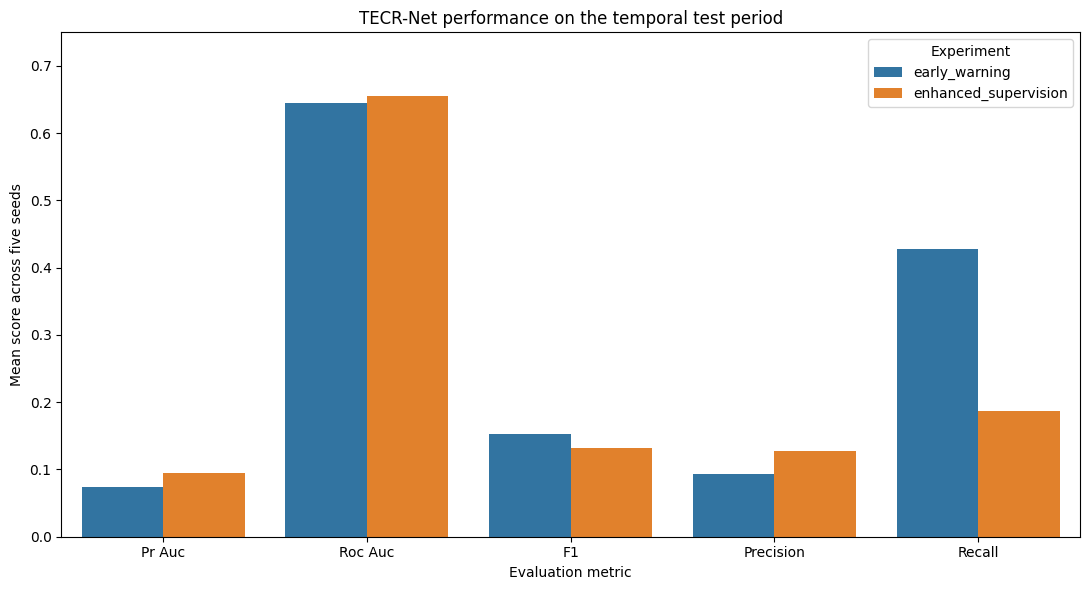

Figure saved: /kaggle/working/bsee_tecrnet_results/tecrnet_test_performance.png


In [4]:
plot_data = test_results[
    [
        "experiment",
        "pr_auc_mean",
        "pr_auc_std",
        "roc_auc_mean",
        "roc_auc_std",
        "f1_mean",
        "precision_mean",
        "recall_mean",
    ]
].copy()

long_data = plot_data.melt(
    id_vars="experiment",
    value_vars=[
        "pr_auc_mean",
        "roc_auc_mean",
        "f1_mean",
        "precision_mean",
        "recall_mean",
    ],
    var_name="metric",
    value_name="score",
)

long_data["metric"] = long_data[
    "metric"
].str.replace(
    "_mean",
    "",
    regex=False,
).str.replace(
    "_",
    " ",
).str.title()

plt.figure(
    figsize=(11, 6)
)

sns.barplot(
    data=long_data,
    x="metric",
    y="score",
    hue="experiment",
)

plt.title(
    "TECR-Net performance on the temporal test period"
)

plt.xlabel(
    "Evaluation metric"
)

plt.ylabel(
    "Mean score across five seeds"
)

plt.ylim(
    0,
    max(
        0.75,
        long_data["score"].max() + 0.05,
    ),
)

plt.legend(
    title="Experiment"
)

plt.tight_layout()

figure_path = (
    RESULT_DIR
    / "tecrnet_test_performance.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved:",
    figure_path,
)

In [5]:
sequence_index = pd.read_csv(
    RESULT_DIR
    / "sequence_index.csv"
)

test_sequence_index = sequence_index[
    sequence_index["feature_year"].between(
        2022,
        2024,
    )
].copy()

test_prevalence = (
    test_sequence_index["target"].mean()
)

operational_results = []

for _, row in test_results.iterrows():
    experiment = row["experiment"]

    for k in [
        50,
        100,
        200,
    ]:
        precision_at_k = row[
            f"precision_at_{k}_mean"
        ]

        lift = (
            precision_at_k
            / test_prevalence
        )

        operational_results.append(
            {
                "experiment": experiment,
                "k": k,
                "test_prevalence": test_prevalence,
                "precision_at_k": precision_at_k,
                "lift_over_random": lift,
            }
        )

operational_table = pd.DataFrame(
    operational_results
)

display(
    operational_table.round(4)
)

operational_table.to_csv(
    RESULT_DIR
    / "operational_lift.csv",
    index=False,
)

,experiment,k,test_prevalence,precision_at_k,lift_over_random
0,early_warning,50,0.0428,0.044,1.0279
1,early_warning,100,0.0428,0.056,1.3083
2,early_warning,200,0.0428,0.082,1.9157
3,enhanced_supervision,50,0.0428,0.160,3.7379
4,enhanced_supervision,100,0.0428,0.124,2.8969
5,enhanced_supervision,200,0.0428,0.100,2.3362


In [6]:
"""TECR-Net: proposed temporal compliance-risk model for BSEE platforms.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset


LOG = logging.getLogger("tecrnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33, 44, 55]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 12
TUNING_SEED = 2026
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecrnet_results")
EXPERIMENTS = ["early_warning", "enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        _, hidden_state = self.temporal(dynamic)
        temporal = torch.cat([hidden_state[-2], hidden_state[-1]], dim=1)
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    hidden = trial.suggest_categorical("hidden", [32, 48, 64, 96])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_int("gru_layers", 1, 3),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.10, 0.40),
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.0, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        seed_everything(TUNING_SEED)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(TUNING_SEED), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
        loss_function = FocalLoss(
            alpha=positive_alpha, gamma=float(params["focal_gamma"])
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for epoch in range(1, MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()

                validation_logits, _ = predict(model, validation_loader, device)
                if not np.isfinite(validation_logits).all():
                    raise FloatingPointError("Non-finite validation logits")
                probability = 1 / (
                    1 + np.exp(-np.clip(validation_logits, -30, 30))
                )
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                trial.report(score, step=epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= PATIENCE:
                        break
            return best_score
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    pruner = optuna.pruners.MedianPruner(
        n_startup_trials=5, n_warmup_steps=10, interval_steps=5
    )
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(validation_logits.reshape(-1, 1), arrays["validation"]["target"])
    validation_probability = calibrator.predict_proba(validation_logits.reshape(-1, 1))[:, 1]
    test_probability = calibrator.predict_proba(test_logits.reshape(-1, 1))[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "pr_auc": float(average_precision_score(target, probability)),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s TECR-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "TECR-Net",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Net", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": "validation PR-AUC",
        "loss": "class-balanced focal loss",
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecrnet_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nTECR-Net five-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 05:38:08,992 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 05:38:10,760 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 05:39:20,080 INFO Tuning early_warning TECR-Net with 12 trials
[I 2026-10-08 05:39:20,082] A new study created in memory with name: tecrnet_early_warning


  0%|          | 0/12 [00:00<?, ?it/s]

[I 2026-10-08 05:39:32,053] Trial 0 finished with value: 0.06651351371302594 and parameters: {'hidden': 64, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.2674750344597575, 'learning_rate': 0.0014352412082031885, 'weight_decay': 8.080342487592334e-06, 'focal_gamma': 1.7946019869724685, 'batch_size': 256}. Best is trial 0 with value: 0.06651351371302594.
[I 2026-10-08 05:39:44,967] Trial 1 finished with value: 0.05679731135894522 and parameters: {'hidden': 96, 'gru_layers': 3, 'attention_heads': 8, 'dropout': 0.2928690849325514, 'learning_rate': 0.00022310152372121493, 'weight_decay': 0.000795421468696945, 'focal_gamma': 1.298334266146705, 'batch_size': 512}. Best is trial 0 with value: 0.06651351371302594.
[I 2026-10-08 05:39:54,902] Trial 2 finished with value: 0.059639818122017116 and parameters: {'hidden': 32, 'gru_layers': 1, 'attention_heads': 4, 'dropout': 0.1621540000644266, 'learning_rate': 0.00046345726092126736, 'weight_decay': 0.000660368854542824, 'focal_gamma': 1.6235

2026-10-08 05:42:25,539 INFO Best early_warning parameters: {'hidden': 32, 'gru_layers': 3, 'attention_heads': 8, 'dropout': 0.15046222765117231, 'learning_rate': 0.0003192254425731603, 'weight_decay': 4.00053893874061e-05, 'focal_gamma': 1.7377095676175456, 'batch_size': 128}
2026-10-08 05:42:25,540 INFO Training early_warning, seed 11


[I 2026-10-08 05:42:25,522] Trial 11 finished with value: 0.06950667342646177 and parameters: {'hidden': 48, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.16605857568246155, 'learning_rate': 0.0002531627326102408, 'weight_decay': 5.712460450990956e-05, 'focal_gamma': 1.0602180643768793, 'batch_size': 128}. Best is trial 4 with value: 0.07158743187599766.


...

[I 2026-10-08 05:46:00,873] Trial 0 finished with value: 0.07244410091705147 and parameters: {'hidden': 64, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.2674750344597575, 'learning_rate': 0.0014352412082031885, 'weight_decay': 8.080342487592334e-06, 'focal_gamma': 1.7946019869724685, 'batch_size': 256}. Best is trial 0 with value: 0.07244410091705147.
[I 2026-10-08 05:46:10,321] Trial 1 finished with value: 0.07274638503417381 and parameters: {'hidden': 96, 'gru_layers': 3, 'attention_heads': 8, 'dropout': 0.2928690849325514, 'learning_rate': 0.00022310152372121493, 'weight_decay': 0.000795421468696945, 'focal_gamma': 1.298334266146705, 'batch_size': 512}. Best is trial 1 with value: 0.07274638503417381.
[I 2026-10-08 05:46:16,846] Trial 2 finished with value: 0.07646069954214856 and parameters: {'hidden': 32, 'gru_layers': 1, 'attention_heads': 4, 'dropout': 0.1621540000644266, 'learning_rate': 0.00046345726092126736, 'weight_decay': 0.000660368854542824, 'focal_gamma': 1.62350

2026-10-08 05:47:43,323 INFO Best enhanced_supervision parameters: {'hidden': 64, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.3115864682382574, 'learning_rate': 0.002503627454282011, 'weight_decay': 1.4730260987952989e-06, 'focal_gamma': 1.7982607813900484, 'batch_size': 256}
2026-10-08 05:47:43,324 INFO Training enhanced_supervision, seed 11


[I 2026-10-08 05:47:43,313] Trial 11 pruned. 


2026-10-08 05:47:57,337 INFO Training enhanced_supervision, seed 22
2026-10-08 05:48:07,240 INFO Training enhanced_supervision, seed 33
2026-10-08 05:48:21,995 INFO Training enhanced_supervision, seed 44
2026-10-08 05:48:34,078 INFO Training enhanced_supervision, seed 55



TECR-Net five-seed summary
          experiment      split  best_epoch_mean  pr_auc_mean  roc_auc_mean  f1_mean  precision_mean  recall_mean  balanced_accuracy_mean  brier_score_mean  threshold_mean  tn_mean  fp_mean  fn_mean  tp_mean  precision_at_50_mean  recall_at_50_mean  precision_at_100_mean  recall_at_100_mean  precision_at_200_mean  recall_at_200_mean  runtime_seconds_mean  best_epoch_std  pr_auc_std  roc_auc_std   f1_std  precision_std  recall_std  balanced_accuracy_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  precision_at_100_std  recall_at_100_std  precision_at_200_std  recall_at_200_std  runtime_seconds_std
       early_warning       test             13.6     0.073508      0.644072 0.134328        0.087792     0.355319                0.594406          0.040620        0.051855   1752.0    350.0     60.6     33.4                 0.060           0.031915                  0.072            0.076596        

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RESULT_DIR = Path(
    "/kaggle/working/bsee_tecrnet_results"
)

SUMMARY_PATH = (
    RESULT_DIR
    / "five_seed_summary.csv"
)

if not SUMMARY_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {SUMMARY_PATH}"
    )

summary = pd.read_csv(
    SUMMARY_PATH
)

test_results = (
    summary[
        summary["split"] == "test"
    ]
    .copy()
    .reset_index(drop=True)
)

metrics_table = test_results[
    [
        "experiment",
        "pr_auc_mean",
        "pr_auc_std",
        "roc_auc_mean",
        "roc_auc_std",
        "f1_mean",
        "f1_std",
        "precision_mean",
        "precision_std",
        "recall_mean",
        "recall_std",
        "balanced_accuracy_mean",
        "balanced_accuracy_std",
        "brier_score_mean",
        "brier_score_std",
    ]
].copy()

display(
    metrics_table.round(4)
)

,experiment,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,balanced_accuracy_mean,balanced_accuracy_std,brier_score_mean,brier_score_std
0,early_warning,0.0735,0.0056,0.6441,0.0034,0.1343,0.0185,0.0878,0.0057,0.3553,0.1757,0.5944,0.0467,0.0406,0.0
1,enhanced_supervision,0.0851,0.0078,0.6430,0.0134,0.1251,0.0283,0.1167,0.0467,0.2319,0.1825,0.5649,0.0423,0.0406,0.0


In [8]:
def mean_std(
    mean_value,
    standard_deviation,
):
    return (
        f"{mean_value:.4f} "
        f"± {standard_deviation:.4f}"
    )


formatted_rows = []

for _, row in test_results.iterrows():
    formatted_rows.append(
        {
            "Experiment": row["experiment"],
            "PR-AUC": mean_std(
                row["pr_auc_mean"],
                row["pr_auc_std"],
            ),
            "ROC-AUC": mean_std(
                row["roc_auc_mean"],
                row["roc_auc_std"],
            ),
            "F1": mean_std(
                row["f1_mean"],
                row["f1_std"],
            ),
            "Precision": mean_std(
                row["precision_mean"],
                row["precision_std"],
            ),
            "Recall": mean_std(
                row["recall_mean"],
                row["recall_std"],
            ),
            "Balanced accuracy": mean_std(
                row["balanced_accuracy_mean"],
                row["balanced_accuracy_std"],
            ),
            "Brier score": mean_std(
                row["brier_score_mean"],
                row["brier_score_std"],
            ),
        }
    )

formatted_table = pd.DataFrame(
    formatted_rows
)

display(formatted_table)

formatted_table.to_csv(
    RESULT_DIR
    / "publication_metrics_table.csv",
    index=False,
)

,Experiment,PR-AUC,ROC-AUC,F1,Precision,Recall,Balanced accuracy,Brier score
0,early_warning,0.0735 ± 0.0056,0.6441 ± 0.0034,0.1343 ± 0.0185,0.0878 ± 0.0057,0.3553 ± 0.1757,0.5944 ± 0.0467,0.0406 ± 0.0000
1,enhanced_supervision,0.0851 ± 0.0078,0.6430 ± 0.0134,0.1251 ± 0.0283,0.1167 ± 0.0467,0.2319 ± 0.1825,0.5649 ± 0.0423,0.0406 ± 0.0000


In [9]:
TEST_PREVALENCE = 0.0428

operational_rows = []

for _, row in test_results.iterrows():
    for k in [
        50,
        100,
        200,
    ]:
        precision_at_k = row[
            f"precision_at_{k}_mean"
        ]

        recall_at_k = row[
            f"recall_at_{k}_mean"
        ]

        operational_rows.append(
            {
                "experiment": row["experiment"],
                "k": k,
                "test_prevalence": TEST_PREVALENCE,
                "precision_at_k": precision_at_k,
                "recall_at_k": recall_at_k,
                "lift_at_k": (
                    precision_at_k
                    / TEST_PREVALENCE
                ),
            }
        )

operational_table = pd.DataFrame(
    operational_rows
)

display(
    operational_table.round(4)
)

operational_table.to_csv(
    RESULT_DIR
    / "publication_operational_table.csv",
    index=False,
)

,experiment,k,test_prevalence,precision_at_k,recall_at_k,lift_at_k
0,early_warning,50,0.0428,0.060,0.0319,1.4019
1,early_warning,100,0.0428,0.072,0.0766,1.6822
2,early_warning,200,0.0428,0.087,0.1851,2.0327
3,enhanced_supervision,50,0.0428,0.124,0.0660,2.8972
4,enhanced_supervision,100,0.0428,0.106,0.1128,2.4766
5,enhanced_supervision,200,0.0428,0.094,0.2000,2.1963


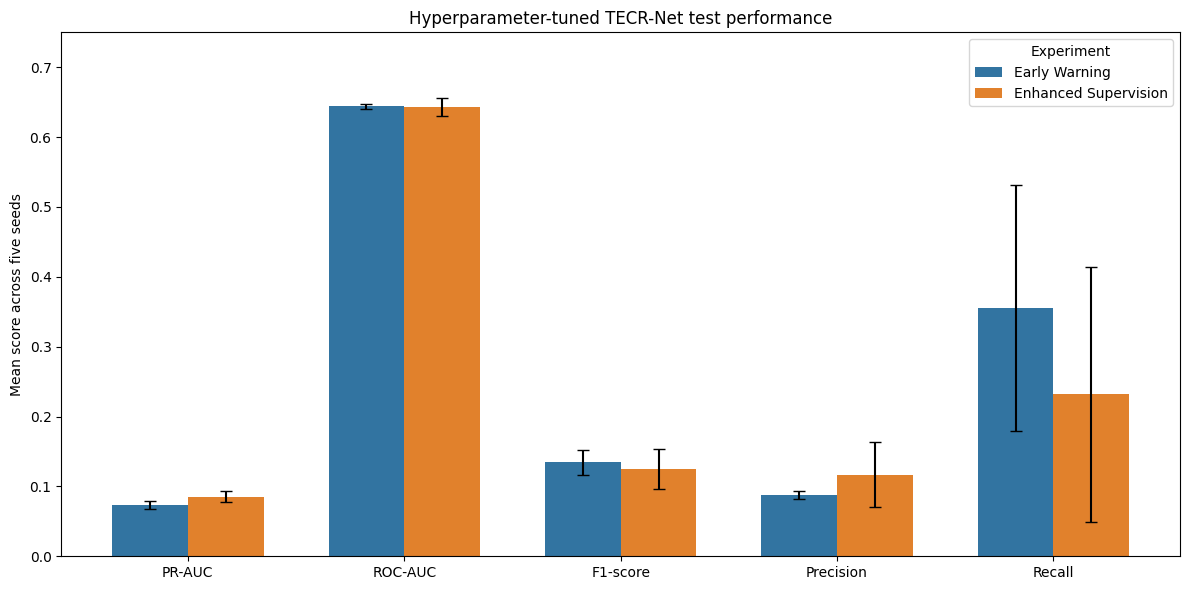

Saved: /kaggle/working/bsee_tecrnet_results/tuned_tecrnet_test_metrics.png


In [10]:
plot_metrics = [
    ("pr_auc", "PR-AUC"),
    ("roc_auc", "ROC-AUC"),
    ("f1", "F1-score"),
    ("precision", "Precision"),
    ("recall", "Recall"),
]

experiments = test_results[
    "experiment"
].tolist()

x = np.arange(
    len(plot_metrics)
)

width = 0.35

fig, ax = plt.subplots(
    figsize=(12, 6)
)

colors = [
    "#3274A1",
    "#E1812C",
]

for experiment_index, experiment in enumerate(
    experiments
):
    row = test_results[
        test_results["experiment"]
        == experiment
    ].iloc[0]

    means = [
        row[f"{metric}_mean"]
        for metric, _ in plot_metrics
    ]

    standard_deviations = [
        row[f"{metric}_std"]
        for metric, _ in plot_metrics
    ]

    positions = (
        x
        + (
            experiment_index
            - 0.5
        )
        * width
    )

    ax.bar(
        positions,
        means,
        width=width,
        yerr=standard_deviations,
        capsize=4,
        label=experiment.replace(
            "_",
            " ",
        ).title(),
        color=colors[
            experiment_index
        ],
    )

ax.set_xticks(x)

ax.set_xticklabels(
    [
        label
        for _, label in plot_metrics
    ]
)

ax.set_ylabel(
    "Mean score across five seeds"
)

ax.set_title(
    "Hyperparameter-tuned TECR-Net test performance"
)

ax.legend(
    title="Experiment"
)

ax.set_ylim(
    0,
    0.75,
)

plt.tight_layout()

plot_path = (
    RESULT_DIR
    / "tuned_tecrnet_test_metrics.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    plot_path,
)

In [11]:
"""TECR-Net: proposed temporal compliance-risk model for BSEE platforms.

For each platform, three genuinely consecutive feature years (t-2,t-1,t)
predict whether an INC occurs in t+1. Preprocessing is fitted on training
sequences only. Validation years select epochs, calibration, and thresholds;
test years are used only for final evaluation.
"""

from __future__ import annotations

import copy
import json
import logging
import math
import random
import shutil
import time
from pathlib import Path

import numpy as np
import lightgbm as lgb
import optuna
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from torch import nn
from torch.utils.data import DataLoader, Dataset


LOG = logging.getLogger("tecrnet")
TARGET = "next_year_any_inc"
SEQUENCE_LENGTH = 3
SEEDS = [11, 22, 33]
MAX_EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 256
N_TRIALS = 12
TUNING_SEED = 2026
OUTPUT_ROOT = Path("/kaggle/working/bsee_tecr_hybrid_results")
EXPERIMENTS = ["early_warning", "enhanced_supervision"]

TRAIN_YEARS = range(2014, 2020)
VALIDATION_YEARS = range(2020, 2022)
TEST_YEARS = range(2022, 2025)

STATIC_NUMERIC = ["water_depth", "latitude", "longitude"]

DYNAMIC_NUMERIC_BASE = [
    "active_months", "producing_wells_mean", "producing_wells_max",
    "bopd_mean", "bopd_max", "mcfd_mean", "mcfd_max", "boepd_mean",
    "bwpd_mean", "platform_age", "operator_facilities_inspected",
    "operator_inspection_records", "operator_inspection_types",
    "investigated_accident_count", "accident_type_count",
    "previous_year_inc_count", "inc_count_previous_3_observations",
    "previous_year_accident_count", "production_change_bopd",
    "production_change_mcfd",
]

COMPLIANCE_NUMERIC = [
    "inc_count", "enforcement_code_count", "any_inc",
    "operator_warning_incs", "operator_component_shutin_incs",
    "operator_facility_shutin_incs",
]

CATEGORICAL = [
    "area_code", "region_code", "structure_type", "major_structure_flag",
    "district_code", "heliport_flag", "attended_8hr_flag",
    "manned_24hr_flag",
]


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_model_csv() -> Path:
    direct = [
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv"),
        Path("/kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv.gz"),
        Path("/kaggle/working/bsee_processed/bsee_platform_year_model.csv"),
    ]
    for path in direct:
        if path.is_file():
            return path
    matches = []
    for root in [Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            matches += list(root.rglob("bsee_platform_year_model.csv"))
            matches += list(root.rglob("bsee_platform_year_model.csv.gz"))
    if not matches:
        raise FileNotFoundError("Could not locate bsee_platform_year_model.csv(.gz).")
    return matches[0]


def validate_frame(frame: pd.DataFrame) -> None:
    required = {
        "platform_id", "year", TARGET, *STATIC_NUMERIC,
        *DYNAMIC_NUMERIC_BASE, *COMPLIANCE_NUMERIC, *CATEGORICAL,
    }
    missing = sorted(required.difference(frame.columns))
    if missing:
        raise ValueError("Required columns missing:\n" + "\n".join(missing))
    duplicates = int(frame.duplicated(["platform_id", "year"]).sum())
    if duplicates:
        raise ValueError(f"Found {duplicates} duplicate platform-year records.")


def build_sequence_index(frame: pd.DataFrame) -> pd.DataFrame:
    """Return row indices for consecutive t-2,t-1,t windows."""
    frame.sort_values(["platform_id", "year"], inplace=True)
    frame.reset_index(drop=True, inplace=True)
    records = []
    for platform_id, group in frame.groupby("platform_id", sort=False):
        years_to_index = dict(zip(group["year"].astype(int), group.index))
        for feature_year, row_index in years_to_index.items():
            if feature_year < min(TRAIN_YEARS) or feature_year > max(TEST_YEARS):
                continue
            needed = [feature_year - 2, feature_year - 1, feature_year, feature_year + 1]
            if not all(year in years_to_index for year in needed):
                continue
            # Rebuild the label directly from the immediately following
            # calendar year. This prevents a row shift across a year gap.
            next_year_inc_count = pd.to_numeric(
                frame.at[years_to_index[feature_year + 1], "inc_count"],
                errors="coerce",
            )
            if pd.isna(next_year_inc_count):
                continue
            target = int(next_year_inc_count > 0)
            records.append({
                "platform_id": platform_id,
                "feature_year": feature_year,
                "target_year": feature_year + 1,
                "row_t_minus_2": years_to_index[feature_year - 2],
                "row_t_minus_1": years_to_index[feature_year - 1],
                "row_t": years_to_index[feature_year],
                "target": int(target),
            })
    index = pd.DataFrame(records)
    if index.empty:
        raise ValueError("No consecutive three-year platform sequences were constructed.")
    return index


class NumericProcessor:
    """Training-only quantile capping, median imputation, robust scaling."""

    def fit(self, values: np.ndarray):
        values = np.asarray(values, dtype=np.float64)
        # Production-change ratios can contain +/-inf after division by zero.
        # Treat every non-finite value as missing before learning statistics.
        values = values.copy()
        values[~np.isfinite(values)] = np.nan

        n_features = values.shape[1]
        self.lower = np.zeros(n_features, dtype=np.float64)
        self.upper = np.zeros(n_features, dtype=np.float64)
        self.median = np.zeros(n_features, dtype=np.float64)
        self.all_missing = np.zeros(n_features, dtype=bool)

        # Calculate column-wise to handle completely missing training columns
        # without allowing NaN preprocessing parameters.
        for column_index in range(n_features):
            column = values[:, column_index]
            finite = column[np.isfinite(column)]
            if finite.size == 0:
                self.all_missing[column_index] = True
                self.lower[column_index] = 0.0
                self.upper[column_index] = 0.0
                self.median[column_index] = 0.0
            else:
                self.lower[column_index] = np.quantile(finite, 0.01)
                self.upper[column_index] = np.quantile(finite, 0.99)
                clipped_column = np.clip(
                    finite,
                    self.lower[column_index],
                    self.upper[column_index],
                )
                self.median[column_index] = np.median(clipped_column)

        clipped = np.clip(values, self.lower, self.upper)
        filled = np.where(np.isnan(clipped), self.median, clipped)
        self.center = np.median(filled, axis=0)
        q25 = np.quantile(filled, 0.25, axis=0)
        q75 = np.quantile(filled, 0.75, axis=0)
        self.scale = q75 - q25
        invalid_scale = (~np.isfinite(self.scale)) | (np.abs(self.scale) < 1e-8)
        self.scale[invalid_scale] = 1.0

        for parameter_name in ["lower", "upper", "median", "center", "scale"]:
            parameter = getattr(self, parameter_name)
            if not np.isfinite(parameter).all():
                raise ValueError(
                    f"NumericProcessor produced non-finite {parameter_name} values."
                )
        return self

    def transform(self, values: np.ndarray) -> np.ndarray:
        values = np.asarray(values, dtype=np.float64)
        values = values.copy()
        values[~np.isfinite(values)] = np.nan
        values = np.clip(values, self.lower, self.upper)
        values = np.where(np.isnan(values), self.median, values)
        transformed = (values - self.center) / self.scale
        transformed[:, self.all_missing] = 0.0
        transformed = np.nan_to_num(
            transformed,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        )
        return transformed.astype(np.float32)

    def state(self) -> dict:
        return {name: getattr(self, name).tolist() for name in [
            "lower", "upper", "median", "center", "scale", "all_missing"
        ]}


class CategoryProcessor:
    def fit(self, frame: pd.DataFrame, columns: list[str]):
        self.columns = columns
        self.vocabularies = {}
        for column in columns:
            values = frame[column].fillna("Unknown").astype(str)
            categories = sorted(values.unique().tolist())
            self.vocabularies[column] = {value: i + 1 for i, value in enumerate(categories)}
        return self

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        output = np.zeros((len(frame), len(self.columns)), dtype=np.int64)
        for j, column in enumerate(self.columns):
            mapping = self.vocabularies[column]
            values = frame[column].fillna("Unknown").astype(str)
            output[:, j] = values.map(mapping).fillna(0).astype(np.int64)
        return output

    @property
    def cardinalities(self) -> list[int]:
        return [len(self.vocabularies[column]) + 1 for column in self.columns]


def prepare_arrays(frame: pd.DataFrame, sequence_index: pd.DataFrame,
                   experiment: str) -> tuple[dict, dict]:
    dynamic_columns = DYNAMIC_NUMERIC_BASE.copy()
    if experiment == "enhanced_supervision":
        dynamic_columns += COMPLIANCE_NUMERIC

    train_samples = sequence_index[sequence_index["feature_year"].isin(TRAIN_YEARS)]
    validation_samples = sequence_index[sequence_index["feature_year"].isin(VALIDATION_YEARS)]
    test_samples = sequence_index[sequence_index["feature_year"].isin(TEST_YEARS)]
    if min(len(train_samples), len(validation_samples), len(test_samples)) == 0:
        raise ValueError("At least one temporal sequence split is empty.")

    sequence_row_columns = ["row_t_minus_2", "row_t_minus_1", "row_t"]
    train_context_indices = np.unique(train_samples[sequence_row_columns].to_numpy().ravel())

    dynamic_processor = NumericProcessor().fit(
        frame.loc[train_context_indices, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    static_processor = NumericProcessor().fit(
        frame.loc[train_samples["row_t"], STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
    )
    category_processor = CategoryProcessor().fit(
        frame.loc[train_samples["row_t"], CATEGORICAL], CATEGORICAL
    )

    def convert(samples: pd.DataFrame) -> dict:
        row_matrix = samples[sequence_row_columns].to_numpy(dtype=np.int64)
        dynamic = np.stack([
            dynamic_processor.transform(
                frame.loc[rows, dynamic_columns].apply(pd.to_numeric, errors="coerce").to_numpy()
            ) for rows in row_matrix
        ])
        current_rows = samples["row_t"].to_numpy(dtype=np.int64)
        static = static_processor.transform(
            frame.loc[current_rows, STATIC_NUMERIC].apply(pd.to_numeric, errors="coerce").to_numpy()
        )
        categorical = category_processor.transform(frame.loc[current_rows, CATEGORICAL])
        return {
            "dynamic": dynamic,
            "static": static,
            "categorical": categorical,
            "target": samples["target"].to_numpy(dtype=np.float32),
            "metadata": samples[["platform_id", "feature_year", "target_year"]].reset_index(drop=True),
        }

    arrays = {
        "train": convert(train_samples),
        "validation": convert(validation_samples),
        "test": convert(test_samples),
    }
    for split_name, split_values in arrays.items():
        for array_name in ["dynamic", "static"]:
            if not np.isfinite(split_values[array_name]).all():
                raise ValueError(
                    f"Non-finite values remain in {experiment}/{split_name}/{array_name}."
                )
    preprocessing = {
        "dynamic_columns": dynamic_columns,
        "static_columns": STATIC_NUMERIC,
        "categorical_columns": CATEGORICAL,
        "dynamic_processor": dynamic_processor.state(),
        "static_processor": static_processor.state(),
        "category_vocabularies": category_processor.vocabularies,
        "cardinalities": category_processor.cardinalities,
    }
    return arrays, preprocessing


class SequenceDataset(Dataset):
    def __init__(self, arrays: dict):
        self.dynamic = torch.from_numpy(arrays["dynamic"])
        self.static = torch.from_numpy(arrays["static"])
        self.categorical = torch.from_numpy(arrays["categorical"])
        self.target = torch.from_numpy(arrays["target"])

    def __len__(self):
        return len(self.target)

    def __getitem__(self, index):
        return self.dynamic[index], self.static[index], self.categorical[index], self.target[index]


class TECRNet(nn.Module):
    """Temporal encoder plus static/categorical encoders and modality attention."""

    def __init__(self, n_dynamic: int, n_static: int, cardinalities: list[int],
                 hidden: int = 64, dropout: float = 0.25,
                 gru_layers: int = 2, attention_heads: int = 4):
        super().__init__()
        self.temporal = nn.GRU(
            input_size=n_dynamic, hidden_size=hidden, num_layers=gru_layers,
            dropout=dropout if gru_layers > 1 else 0.0,
            batch_first=True, bidirectional=True,
        )
        self.temporal_projection = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.LayerNorm(hidden)
        )
        self.static_encoder = nn.Sequential(
            nn.Linear(n_static, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden), nn.LayerNorm(hidden),
        )
        embedding_dims = [min(16, max(3, int(round(math.sqrt(cardinality)))))
                          for cardinality in cardinalities]
        self.embeddings = nn.ModuleList([
            nn.Embedding(cardinality, dimension, padding_idx=0)
            for cardinality, dimension in zip(cardinalities, embedding_dims)
        ])
        self.category_encoder = nn.Sequential(
            nn.Linear(sum(embedding_dims), hidden), nn.GELU(),
            nn.Dropout(dropout), nn.LayerNorm(hidden),
        )
        self.modality_attention = nn.MultiheadAttention(
            embed_dim=hidden, num_heads=attention_heads,
            dropout=dropout, batch_first=True
        )
        self.query = nn.Parameter(torch.zeros(1, 1, hidden))
        nn.init.normal_(self.query, std=0.02)
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, dynamic, static, categorical):
        _, hidden_state = self.temporal(dynamic)
        temporal = torch.cat([hidden_state[-2], hidden_state[-1]], dim=1)
        temporal = self.temporal_projection(temporal)
        static_token = self.static_encoder(static)
        embedded = torch.cat([
            embedding(categorical[:, i]) for i, embedding in enumerate(self.embeddings)
        ], dim=1)
        category_token = self.category_encoder(embedded)
        modalities = torch.stack([temporal, static_token, category_token], dim=1)
        query = self.query.expand(dynamic.size(0), -1, -1)
        attended, attention = self.modality_attention(
            query=query, key=modalities, value=modalities,
            need_weights=True, average_attn_weights=True,
        )
        fused = torch.cat([attended.squeeze(1), modalities.mean(dim=1)], dim=1)
        return self.classifier(fused).squeeze(1), attention.squeeze(1)


class FocalLoss(nn.Module):
    def __init__(self, alpha: float, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, targets):
        probability = torch.sigmoid(logits)
        ce = nn.functional.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        pt = probability * targets + (1 - probability) * (1 - targets)
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * (1 - pt).pow(self.gamma) * ce).mean()


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, device: torch.device) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    logits, attentions = [], []
    for dynamic, static, categorical, _target in loader:
        output, attention = model(
            dynamic.to(device), static.to(device), categorical.to(device)
        )
        logits.append(output.cpu().numpy())
        attentions.append(attention.cpu().numpy())
    return np.concatenate(logits), np.concatenate(attentions)


def suggest_parameters(trial: optuna.Trial) -> dict:
    hidden = trial.suggest_categorical("hidden", [32, 48, 64, 96])
    valid_heads = [heads for heads in [2, 4, 8] if hidden % heads == 0]
    return {
        "hidden": hidden,
        "gru_layers": trial.suggest_int("gru_layers", 1, 3),
        "attention_heads": trial.suggest_categorical("attention_heads", valid_heads),
        "dropout": trial.suggest_float("dropout", 0.10, 0.40),
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-4, 3e-3, log=True
        ),
        "weight_decay": trial.suggest_float(
            "weight_decay", 1e-6, 1e-3, log=True
        ),
        "focal_gamma": trial.suggest_float("focal_gamma", 1.0, 3.0),
        "batch_size": trial.suggest_categorical("batch_size", [128, 256, 512]),
    }


def flatten_sequence_features(split: dict) -> np.ndarray:
    """Summarize each sequence for the gradient-boosting branch."""
    dynamic = split["dynamic"]
    summaries = [
        dynamic[:, -1, :],
        dynamic.mean(axis=1),
        dynamic.std(axis=1),
        dynamic.min(axis=1),
        dynamic.max(axis=1),
        dynamic[:, -1, :] - dynamic[:, 0, :],
        split["static"],
        split["categorical"].astype(np.float32),
    ]
    output = np.concatenate(summaries, axis=1).astype(np.float32)
    if not np.isfinite(output).all():
        raise ValueError("Non-finite flattened sequence features detected.")
    return output


def suggest_lightgbm_parameters(trial: optuna.Trial) -> dict:
    return {
        "n_estimators": 2500,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 12, 64),
        "max_depth": trial.suggest_int("max_depth", 3, 9),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 150),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.55, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 20.0, log=True),
    }


def tune_lightgbm(arrays: dict, experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune the sequence-summary branch using validation PR-AUC only."""
    X_train = flatten_sequence_features(arrays["train"])
    X_validation = flatten_sequence_features(arrays["validation"])
    y_train = arrays["train"]["target"].astype(int)
    y_validation = arrays["validation"]["target"].astype(int)
    scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

    def objective(trial: optuna.Trial) -> float:
        params = suggest_lightgbm_parameters(trial)
        model = lgb.LGBMClassifier(
            objective="binary", random_state=TUNING_SEED, n_jobs=-1,
            scale_pos_weight=scale_pos_weight, verbosity=-1, **params,
        )
        model.fit(
            X_train, y_train,
            eval_set=[(X_validation, y_validation)],
            eval_metric="average_precision",
            callbacks=[lgb.early_stopping(100, verbose=False)],
        )
        probability = model.predict_proba(X_validation)[:, 1]
        return float(average_precision_score(y_validation, probability))

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=TUNING_SEED),
        study_name=f"tecr_hybrid_lightgbm_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    best = suggest_lightgbm_parameters(
        optuna.trial.FixedTrial(study.best_params)
    )
    return best, study.trials_dataframe()


def tune_hyperparameters(arrays: dict, preprocessing: dict,
                         experiment: str) -> tuple[dict, pd.DataFrame]:
    """Tune on validation PR-AUC without reading or predicting the test set."""

    def objective(trial: optuna.Trial) -> float:
        params = suggest_parameters(trial)
        seed_everything(TUNING_SEED)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        train_dataset = SequenceDataset(arrays["train"])
        validation_dataset = SequenceDataset(arrays["validation"])
        train_loader = DataLoader(
            train_dataset, batch_size=int(params["batch_size"]), shuffle=True,
            generator=torch.Generator().manual_seed(TUNING_SEED), num_workers=0,
            pin_memory=torch.cuda.is_available(),
        )
        validation_loader = DataLoader(
            validation_dataset, batch_size=512, shuffle=False, num_workers=0
        )
        model = TECRNet(
            n_dynamic=arrays["train"]["dynamic"].shape[2],
            n_static=arrays["train"]["static"].shape[1],
            cardinalities=preprocessing["cardinalities"],
            hidden=int(params["hidden"]), dropout=float(params["dropout"]),
            gru_layers=int(params["gru_layers"]),
            attention_heads=int(params["attention_heads"]),
        ).to(device)
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=float(params["learning_rate"]),
            weight_decay=float(params["weight_decay"]),
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
        )
        y_train = arrays["train"]["target"]
        positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
        loss_function = FocalLoss(
            alpha=positive_alpha, gamma=float(params["focal_gamma"])
        )
        best_score, bad_epochs = -np.inf, 0
        try:
            for epoch in range(1, MAX_EPOCHS + 1):
                model.train()
                for dynamic, static, categorical, target in train_loader:
                    optimizer.zero_grad(set_to_none=True)
                    logits, _ = model(
                        dynamic.to(device), static.to(device), categorical.to(device)
                    )
                    loss = loss_function(logits, target.to(device))
                    if not torch.isfinite(loss):
                        raise FloatingPointError("Non-finite training loss")
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    optimizer.step()

                validation_logits, _ = predict(model, validation_loader, device)
                if not np.isfinite(validation_logits).all():
                    raise FloatingPointError("Non-finite validation logits")
                probability = 1 / (
                    1 + np.exp(-np.clip(validation_logits, -30, 30))
                )
                score = float(average_precision_score(
                    arrays["validation"]["target"], probability
                ))
                scheduler.step(score)
                trial.report(score, step=epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()
                if score > best_score + 1e-5:
                    best_score, bad_epochs = score, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= PATIENCE:
                        break
            return best_score
        finally:
            del model
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    sampler = optuna.samplers.TPESampler(seed=TUNING_SEED)
    pruner = optuna.pruners.MedianPruner(
        n_startup_trials=5, n_warmup_steps=10, interval_steps=5
    )
    study = optuna.create_study(
        direction="maximize", sampler=sampler, pruner=pruner,
        study_name=f"tecrnet_{experiment}",
    )
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    completed = [
        trial for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]
    if not completed:
        raise RuntimeError(f"No TECR-Net tuning trial completed for {experiment}.")
    return dict(study.best_params), study.trials_dataframe()


def train_one_seed(arrays: dict, preprocessing: dict, seed: int,
                   experiment_dir: Path | None, params: dict,
                   tree_params: dict,
                   save_outputs: bool = True) -> tuple[list[dict], pd.DataFrame | None, float]:
    seed_everything(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    datasets = {name: SequenceDataset(values) for name, values in arrays.items()}
    generator = torch.Generator().manual_seed(seed)
    batch_size = int(params["batch_size"])
    train_loader = DataLoader(
        datasets["train"], batch_size=batch_size, shuffle=True,
        generator=generator, num_workers=0, pin_memory=torch.cuda.is_available(),
    )
    loaders = {
        name: DataLoader(dataset, batch_size=512, shuffle=False, num_workers=0)
        for name, dataset in datasets.items()
    }
    model = TECRNet(
        n_dynamic=arrays["train"]["dynamic"].shape[2],
        n_static=arrays["train"]["static"].shape[1],
        cardinalities=preprocessing["cardinalities"],
        hidden=int(params["hidden"]),
        dropout=float(params["dropout"]),
        gru_layers=int(params["gru_layers"]),
        attention_heads=int(params["attention_heads"]),
    ).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=5, min_lr=1e-5
    )
    y_train = arrays["train"]["target"]
    positive_alpha = float(np.clip((y_train == 0).mean(), 0.55, 0.95))
    loss_function = FocalLoss(alpha=positive_alpha, gamma=float(params["focal_gamma"]))

    best_score, best_epoch, best_state, bad_epochs = -np.inf, -1, None, 0
    history = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        losses = []
        for dynamic, static, categorical, target in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(
                dynamic.to(device), static.to(device), categorical.to(device)
            )
            loss = loss_function(logits, target.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))

        validation_logits, _ = predict(model, loaders["validation"], device)
        validation_probability = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
        validation_pr_auc = float(average_precision_score(
            arrays["validation"]["target"], validation_probability
        ))
        scheduler.step(validation_pr_auc)
        history.append({
            "epoch": epoch, "training_loss": float(np.mean(losses)),
            "validation_pr_auc": validation_pr_auc,
            "learning_rate": optimizer.param_groups[0]["lr"],
        })
        if validation_pr_auc > best_score + 1e-5:
            best_score, best_epoch = validation_pr_auc, epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break

    if best_state is None:
        raise RuntimeError("Training failed to produce a valid checkpoint.")
    model.load_state_dict(best_state)

    validation_logits, validation_attention = predict(model, loaders["validation"], device)
    test_logits, test_attention = predict(model, loaders["test"], device)

    neural_validation = 1 / (1 + np.exp(-np.clip(validation_logits, -30, 30)))
    neural_test = 1 / (1 + np.exp(-np.clip(test_logits, -30, 30)))

    # Gradient-boosting branch on sequence summaries.
    X_tree_train = flatten_sequence_features(arrays["train"])
    X_tree_validation = flatten_sequence_features(arrays["validation"])
    X_tree_test = flatten_sequence_features(arrays["test"])
    y_tree_train = arrays["train"]["target"].astype(int)
    scale_pos_weight = float(
        (y_tree_train == 0).sum() / (y_tree_train == 1).sum()
    )
    tree_model = lgb.LGBMClassifier(
        objective="binary", random_state=seed, n_jobs=-1,
        scale_pos_weight=scale_pos_weight, verbosity=-1, **tree_params,
    )
    tree_model.fit(
        X_tree_train, y_tree_train,
        eval_set=[(X_tree_validation, arrays["validation"]["target"].astype(int))],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    tree_validation = tree_model.predict_proba(X_tree_validation)[:, 1]
    tree_test = tree_model.predict_proba(X_tree_test)[:, 1]

    # Select the late-fusion weight on validation PR-AUC only.
    fusion_candidates = np.linspace(0.0, 1.0, 21)
    fusion_scores = []
    for neural_weight in fusion_candidates:
        blended = (
            neural_weight * neural_validation
            + (1.0 - neural_weight) * tree_validation
        )
        fusion_scores.append(average_precision_score(
            arrays["validation"]["target"], blended
        ))
    best_fusion_index = int(np.argmax(fusion_scores))
    neural_weight = float(fusion_candidates[best_fusion_index])
    raw_validation_probability = (
        neural_weight * neural_validation
        + (1.0 - neural_weight) * tree_validation
    )
    raw_test_probability = (
        neural_weight * neural_test
        + (1.0 - neural_weight) * tree_test
    )

    # Platt calibration is fitted on validation only; test remains untouched.
    calibrator = LogisticRegression(random_state=seed, solver="lbfgs")
    calibrator.fit(
        raw_validation_probability.reshape(-1, 1),
        arrays["validation"]["target"],
    )
    validation_probability = calibrator.predict_proba(
        raw_validation_probability.reshape(-1, 1)
    )[:, 1]
    test_probability = calibrator.predict_proba(
        raw_test_probability.reshape(-1, 1)
    )[:, 1]
    threshold = select_threshold(arrays["validation"]["target"], validation_probability)

    checkpoint = {
        "model_state": {key: value.cpu() for key, value in model.state_dict().items()},
        "seed": seed, "best_epoch": best_epoch, "best_validation_pr_auc": best_score,
        "neural_params": params,
        "tree_params": tree_params,
        "neural_weight": neural_weight,
        "hybrid_validation_pr_auc": float(fusion_scores[best_fusion_index]),
        "calibrator_coef": calibrator.coef_.tolist(),
        "calibrator_intercept": calibrator.intercept_.tolist(),
        "threshold": threshold,
    }
    if save_outputs:
        if experiment_dir is None:
            raise ValueError("experiment_dir is required when save_outputs=True")
        torch.save(checkpoint, experiment_dir / f"tecrnet_seed_{seed}.pt")
        tree_model.booster_.save_model(
            str(experiment_dir / f"lightgbm_sequence_seed_{seed}.txt")
        )
        pd.DataFrame(history).to_csv(
            experiment_dir / f"history_seed_{seed}.csv", index=False
        )

    prediction_frame = arrays["test"]["metadata"].copy()
    prediction_frame["target"] = arrays["test"]["target"].astype(int)
    prediction_frame["probability"] = test_probability
    prediction_frame["neural_probability"] = neural_test
    prediction_frame["tree_probability"] = tree_test
    prediction_frame["neural_weight"] = neural_weight
    prediction_frame["prediction"] = (test_probability >= threshold).astype(int)
    prediction_frame[["attention_temporal", "attention_static", "attention_categorical"]] = test_attention
    if save_outputs:
        prediction_frame.to_csv(
            experiment_dir / f"test_predictions_seed_{seed}.csv", index=False
        )

    rows = []
    for split, target, probability in [
        ("validation", arrays["validation"]["target"], validation_probability),
        ("test", arrays["test"]["target"], test_probability),
    ]:
        rows.append({"seed": seed, "split": split, "best_epoch": best_epoch,
                     "neural_weight": neural_weight,
                     **calculate_metrics(target, probability, threshold)})
    return rows, prediction_frame if save_outputs else None, best_score


def select_threshold(target: np.ndarray, probability: np.ndarray) -> float:
    candidates = np.unique(probability)
    if len(candidates) > 2000:
        candidates = np.quantile(candidates, np.linspace(0, 1, 2000))
    scores = [f1_score(target, probability >= threshold, zero_division=0)
              for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])


def calculate_metrics(target: np.ndarray, probability: np.ndarray,
                      threshold: float) -> dict:
    target = np.asarray(target, dtype=int)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, prediction, labels=[0, 1]).ravel()
    result = {
        "pr_auc": float(average_precision_score(target, probability)),
        "roc_auc": float(roc_auc_score(target, probability)),
        "f1": float(f1_score(target, prediction, zero_division=0)),
        "precision": float(precision_score(target, prediction, zero_division=0)),
        "recall": float(recall_score(target, prediction, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(target, prediction)),
        "brier_score": float(brier_score_loss(target, probability)),
        "threshold": float(threshold),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    order = np.argsort(-probability)
    positives = max(int(target.sum()), 1)
    for k in [50, 100, 200]:
        effective_k = min(k, len(target))
        hits = int(target[order[:effective_k]].sum())
        result[f"precision_at_{k}"] = hits / effective_k
        result[f"recall_at_{k}"] = hits / positives
    return result


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    numeric = [column for column in results.select_dtypes(include=np.number).columns
               if column != "seed"]
    grouped = results.groupby(["experiment", "split"])[numeric]
    return grouped.mean().add_suffix("_mean").join(
        grouped.std(ddof=1).add_suffix("_std")
    ).reset_index()


def main() -> None:
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
    source = locate_model_csv()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    LOG.info("Reading %s", source)
    frame = pd.read_csv(source, low_memory=False)
    validate_frame(frame)
    sequence_index = build_sequence_index(frame)
    sequence_index.to_csv(OUTPUT_ROOT / "sequence_index.csv", index=False)
    LOG.info("Constructed %d consecutive three-year sequences", len(sequence_index))

    all_results = []
    for experiment in EXPERIMENTS:
        experiment_dir = OUTPUT_ROOT / experiment
        experiment_dir.mkdir(parents=True, exist_ok=True)
        arrays, preprocessing = prepare_arrays(frame, sequence_index, experiment)
        (experiment_dir / "preprocessing.json").write_text(
            json.dumps(preprocessing, indent=2), encoding="utf-8"
        )
        split_summary = []
        for name, values in arrays.items():
            split_summary.append({
                "split": name, "rows": len(values["target"]),
                "platforms": int(values["metadata"]["platform_id"].nunique()),
                "year_start": int(values["metadata"]["feature_year"].min()),
                "year_end": int(values["metadata"]["feature_year"].max()),
                "positive_cases": int(values["target"].sum()),
                "positive_rate": float(values["target"].mean()),
            })
        pd.DataFrame(split_summary).to_csv(experiment_dir / "split_summary.csv", index=False)

        LOG.info("Tuning %s TECR-Net with %d trials", experiment, N_TRIALS)
        best_params, tuning_trials = tune_hyperparameters(
            arrays, preprocessing, experiment
        )
        (experiment_dir / "best_params.json").write_text(
            json.dumps(best_params, indent=2), encoding="utf-8"
        )
        tuning_trials.to_csv(experiment_dir / "optuna_trials.csv", index=False)
        LOG.info("Best %s parameters: %s", experiment, best_params)

        LOG.info("Tuning %s sequence LightGBM with %d trials", experiment, N_TRIALS)
        best_tree_params, tree_trials = tune_lightgbm(arrays, experiment)
        (experiment_dir / "best_lightgbm_params.json").write_text(
            json.dumps(best_tree_params, indent=2), encoding="utf-8"
        )
        tree_trials.to_csv(
            experiment_dir / "lightgbm_optuna_trials.csv", index=False
        )
        LOG.info("Best %s LightGBM parameters: %s", experiment, best_tree_params)

        for seed in SEEDS:
            LOG.info("Training %s, seed %d", experiment, seed)
            started = time.time()
            rows, _, _ = train_one_seed(
                arrays, preprocessing, seed, experiment_dir,
                best_params, best_tree_params, save_outputs=True,
            )
            for row in rows:
                row.update({
                    "experiment": experiment, "model": "TECR-Hybrid",
                    "runtime_seconds": time.time() - started,
                })
                all_results.append(row)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    results = pd.DataFrame(all_results)
    summary = summarize(results)
    results.to_csv(OUTPUT_ROOT / "all_seed_results.csv", index=False)
    summary.to_csv(OUTPUT_ROOT / "five_seed_summary.csv", index=False)
    configuration = {
        "model": "TECR-Hybrid", "sequence_length": SEQUENCE_LENGTH,
        "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "tuning_seed": TUNING_SEED, "n_trials": N_TRIALS,
        "train_feature_years": [2014, 2019],
        "validation_feature_years": [2020, 2021],
        "test_feature_years": [2022, 2024],
        "selection_metric": "validation PR-AUC",
        "loss": "class-balanced focal loss",
        "calibration": "validation-only Platt scaling",
        "threshold": "maximum validation F1",
    }
    (OUTPUT_ROOT / "configuration.json").write_text(
        json.dumps(configuration, indent=2), encoding="utf-8"
    )
    archive = shutil.make_archive(
        "/kaggle/working/bsee_tecr_hybrid_results", "zip",
        root_dir=str(OUTPUT_ROOT.parent), base_dir=OUTPUT_ROOT.name,
    )
    print("\nTECR-Hybrid three-seed summary")
    print(summary.to_string(index=False))
    print(f"\nResults: {OUTPUT_ROOT}")
    print(f"Downloadable ZIP: {archive}")


if __name__ == "__main__":
    main()


2026-10-08 06:01:32,528 INFO Reading /kaggle/input/datasets/kabil908/bsee-preprocessed/bsee_platform_year_model.csv
2026-10-08 06:01:34,556 INFO Constructed 12280 consecutive three-year sequences
2026-10-08 06:02:41,879 INFO Tuning early_warning TECR-Net with 12 trials
[I 2026-10-08 06:02:41,881] A new study created in memory with name: tecrnet_early_warning


  0%|          | 0/12 [00:00<?, ?it/s]

[I 2026-10-08 06:02:53,934] Trial 0 finished with value: 0.06651351371302594 and parameters: {'hidden': 64, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.2674750344597575, 'learning_rate': 0.0014352412082031885, 'weight_decay': 8.080342487592334e-06, 'focal_gamma': 1.7946019869724685, 'batch_size': 256}. Best is trial 0 with value: 0.06651351371302594.
[I 2026-10-08 06:03:06,713] Trial 1 finished with value: 0.05679731135894522 and parameters: {'hidden': 96, 'gru_layers': 3, 'attention_heads': 8, 'dropout': 0.2928690849325514, 'learning_rate': 0.00022310152372121493, 'weight_decay': 0.000795421468696945, 'focal_gamma': 1.298334266146705, 'batch_size': 512}. Best is trial 0 with value: 0.06651351371302594.
[I 2026-10-08 06:03:16,827] Trial 2 finished with value: 0.059639818122017116 and parameters: {'hidden': 32, 'gru_layers': 1, 'attention_heads': 4, 'dropout': 0.1621540000644266, 'learning_rate': 0.00046345726092126736, 'weight_decay': 0.000660368854542824, 'focal_gamma': 1.6235

2026-10-08 06:05:51,065 INFO Best early_warning parameters: {'hidden': 32, 'gru_layers': 3, 'attention_heads': 8, 'dropout': 0.15046222765117231, 'learning_rate': 0.0003192254425731603, 'weight_decay': 4.00053893874061e-05, 'focal_gamma': 1.7377095676175456, 'batch_size': 128}
2026-10-08 06:05:51,066 INFO Tuning early_warning sequence LightGBM with 12 trials
[I 2026-10-08 06:05:51,086] A new study created in memory with name: tecr_hybrid_lightgbm_early_warning


[I 2026-10-08 06:05:51,055] Trial 11 finished with value: 0.06950667342646177 and parameters: {'hidden': 48, 'gru_layers': 2, 'attention_heads': 2, 'dropout': 0.16605857568246155, 'learning_rate': 0.0002531627326102408, 'weight_decay': 5.712460450990956e-05, 'focal_gamma': 1.0602180643768793, 'batch_size': 128}. Best is trial 4 with value: 0.07158743187599766.


...

[I 2026-10-08 06:10:31,402] Trial 10 finished with value: 0.06033673585799596 and parameters: {'learning_rate': 0.0301763737157073, 'num_leaves': 25, 'max_depth': 6, 'min_child_samples': 142, 'subsample': 0.6770817460109296, 'colsample_bytree': 0.824850973767114, 'reg_alpha': 2.3842357781193084, 'reg_lambda': 3.874654168485742}. Best is trial 10 with value: 0.06033673585799596.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
2026-10-08 06:10:31,900 INFO Best enhanced_supervision LightGBM parameters: {'n_estimators': 2500, 'learning_rate': 0.0301763737157073, 'num_leaves': 25, 'max_depth': 6, 'min_child_samples': 142, 'subsample': 0.6770817460109296, 'subsample_freq': 1, 'colsample_bytree': 0.824850973767114, 'reg_alpha': 2.3842357781193084, 'reg_lambda': 3.874654168485742}
2026-10-08 06:10:31,901 INFO Training enhanced_supervision, seed 11


[I 2026-10-08 06:10:31,891] Trial 11 finished with value: 0.05733882270516902 and parameters: {'learning_rate': 0.03377400367333759, 'num_leaves': 29, 'max_depth': 7, 'min_child_samples': 135, 'subsample': 0.6520938532307763, 'colsample_bytree': 0.75950752826314, 'reg_alpha': 0.6516248118052831, 'reg_lambda': 5.941411849853082}. Best is trial 10 with value: 0.06033673585799596.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
2026-10-08 06:10:46,430 INFO Training enhanced_supervision, seed 22
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
2026-10-08 06:10:57,527 INFO Training enhanced_supervision, seed 33
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have v


TECR-Hybrid three-seed summary
          experiment      split  best_epoch_mean  neural_weight_mean  pr_auc_mean  roc_auc_mean  f1_mean  precision_mean  recall_mean  balanced_accuracy_mean  brier_score_mean  threshold_mean     tn_mean    fp_mean   fn_mean   tp_mean  precision_at_50_mean  recall_at_50_mean  precision_at_100_mean  recall_at_100_mean  precision_at_200_mean  recall_at_200_mean  runtime_seconds_mean  best_epoch_std  neural_weight_std  pr_auc_std  roc_auc_std   f1_std  precision_std  recall_std  balanced_accuracy_std  brier_score_std  threshold_std     tn_std     fp_std    fn_std    tp_std  precision_at_50_std  recall_at_50_std  precision_at_100_std  recall_at_100_std  precision_at_200_std  recall_at_200_std  runtime_seconds_std
       early_warning       test        13.333333            0.933333     0.072310      0.645341 0.136000        0.085511     0.379433                0.600040          0.040767        0.043545 1725.000000 377.000000 58.333333 35.666667              0